<a href="https://colab.research.google.com/github/harshiniemohanraj-data/maintenance-optimisation-sensor-data/blob/main/notebooks/GROUP_4_PROJECT_1_PART_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BUSI 6029 — Assignment 2 · Part B



---
## Section A — Imports & Configuration

In [1]:
# ============================================================
# A1. Imports
# ============================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_validate, GridSearchCV, RandomizedSearchCV,
)
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay,
)

# ── Constants ─────────────────────────────────────────────────
RANDOM_STATE = 42
TARGET       = "machine_failure"
np.random.seed(RANDOM_STATE)

# ── Output folders ────────────────────────────────────────────
project_root  = Path.cwd()
output_folder = project_root / "output"
fig_folder    = output_folder / "figures"
for _f in [output_folder, fig_folder]:
    _f.mkdir(parents=True, exist_ok=True)

# ── Chart style ───────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300,
    "figure.facecolor": "white", "axes.facecolor": "#FAFAFA",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E0E0E0", "grid.linewidth": 0.6,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "legend.fontsize": 10,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
})
C_BLUE   = "#378ADD"
C_CORAL  = "#D85A30"
C_GREEN  = "#3B6D11"
C_AMBER  = "#BA7517"
C_NAVY   = "#185FA5"
PALETTE_BINARY = [C_BLUE, C_CORAL]
PALETTE_MODELS = [C_NAVY, C_AMBER, C_GREEN]

print("Part 2 environment ready.")
print(f"Output folder : {output_folder}")
print(f"Figure folder : {fig_folder}")


Part 2 environment ready.
Output folder : /content/output
Figure folder : /content/output/figures


In [2]:
# ============================================================
# A2. Load cleaned dataset
#     Priority order:
#       1. df already in memory from Part 1
#       2. Saved CSV on disk
#       3. Download and clean raw data from UCI
# ============================================================
try:
    _ = df
    print(f"Using df from Part 1 memory — shape: {df.shape}")
except NameError:
    cleaned_path = output_folder / "cleaned_predictive_maintenance_dataset.csv"
    try:
        df = pd.read_csv(cleaned_path)
        print(f"Loaded cleaned CSV from disk — shape: {df.shape}")
    except FileNotFoundError:
        import requests, zipfile
        print("Downloading raw AI4I dataset from UCI ML Repository...")
        AI4I_URL      = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
        data_folder   = output_folder.parent / "data"
        data_folder.mkdir(parents=True, exist_ok=True)
        zip_path      = data_folder / "ai4i_dataset.zip"
        main_csv_path = data_folder / "ai4i2020.csv"
        if not main_csv_path.exists():
            # Added verify=False to bypass SSL certificate verification
            r = requests.get(AI4I_URL, timeout=90, verify=False)
            r.raise_for_status()
            zip_path.write_bytes(r.content)
            with zipfile.ZipFile(zip_path) as zf:
                zf.extractall(data_folder)
        df = pd.read_csv(main_csv_path)
        df.columns = (df.columns.str.strip().str.lower()
                       .str.replace(" ", "_", regex=False)
                       .str.replace("[^a-z0-9_]", "", regex=True))
        df.drop(columns=[c for c in ["udi","product_id"] if c in df.columns], inplace=True)
        df.drop_duplicates(inplace=True)
        if {"process_temperature_k","air_temperature_k"}.issubset(df.columns):
            df["temp_difference_k"] = df["process_temperature_k"] - df["air_temperature_k"]
        if "tool_wear_min" in df.columns:
            df["tool_wear_band"] = pd.cut(
                df["tool_wear_min"],
                bins=[-0.01, 50, 150, np.inf],
                labels=["Low","Medium","High"],
            )
        df.to_csv(cleaned_path, index=False)
        print(f"Cleaned and saved dataset — shape: {df.shape}")

assert TARGET in df.columns, f"Column '{TARGET}' not found."
print(f"Target '{TARGET}' confirmed. Overall failure rate: {df[TARGET].mean():.4f}")


Loaded cleaned CSV from disk — shape: (10000, 14)
Target 'machine_failure' confirmed. Overall failure rate: 0.0339


---
## Section B — Descriptive Analytics

This section profiles the dataset in full before any modelling begins.  
The goal is to understand the key characteristics of the data, the behaviour  
of the target variable, and how each predictor relates to machine failure.


### B1 — Variable Classification Table

In [3]:
# ============================================================
# B1. Variable classification table
#     Role       : target / predictor / identifier / engineered
#     Data type  : numeric (continuous/discrete) / categorical
#     Measurement: nominal / ordinal / interval / ratio
# ============================================================
SUBFAILURE_COLS = [c for c in ["twf","hdf","pwf","osf","rnf"] if c in df.columns]

var_rows = []

# Core sensor variables
sensors = [
    ("air_temperature_k",      "Predictor",  "Numeric – continuous",  "Ratio",   "Ambient air temperature in Kelvin"),
    ("process_temperature_k",  "Predictor",  "Numeric – continuous",  "Ratio",   "Process/component surface temperature in Kelvin"),
    ("rotational_speed_rpm",   "Predictor",  "Numeric – continuous",  "Ratio",   "Spindle / drive rotational speed in RPM"),
    ("torque_nm",              "Predictor",  "Numeric – continuous",  "Ratio",   "Cutting / drive torque in Newton-metres"),
    ("tool_wear_min",          "Predictor",  "Numeric – continuous",  "Ratio",   "Cumulative tool operating time in minutes"),
]
for name, role, dtype, mtype, desc in sensors:
    if name in df.columns:
        var_rows.append({"Variable": name, "Role": role,
                         "Data Type": dtype, "Measurement": mtype,
                         "Description": desc})

# Categorical
if "type" in df.columns:
    var_rows.append({"Variable": "type", "Role": "Predictor",
                     "Data Type": "Categorical", "Measurement": "Nominal",
                     "Description": "Product quality variant: L (low), M (medium), H (high)"})

# Target
var_rows.append({"Variable": TARGET, "Role": "Target",
                 "Data Type": "Binary categorical", "Measurement": "Nominal",
                 "Description": "1 = machine failure occurred, 0 = no failure"})

# Sub-failure columns (descriptive context only)
sub_desc = {
    "twf": "Tool Wear Failure — failure caused by excessive tool wear",
    "hdf": "Heat Dissipation Failure — failure caused by overheating",
    "pwf": "Power Failure — failure caused by power anomaly",
    "osf": "Overstrain Failure — failure caused by mechanical overstrain",
    "rnf": "Random Failure — failure with no specific cause",
}
for col in SUBFAILURE_COLS:
    var_rows.append({"Variable": col, "Role": "Failure subtype (descriptive only)",
                     "Data Type": "Binary categorical", "Measurement": "Nominal",
                     "Description": sub_desc.get(col, "")})

# Engineered features
eng_vars = [
    ("temp_difference_k",    "Engineered predictor", "Numeric – continuous", "Ratio",
     "Process temp minus air temp — thermal stress indicator"),
    ("power_w",        "Engineered predictor", "Numeric – continuous", "Ratio",
     "Torque × angular velocity — mechanical power proxy"),
    ("tool_wear_band", "Engineered predictor", "Categorical",          "Ordinal",
     "Tool wear banded into Low / Medium / High (ordinal)"),
]
for name, role, dtype, mtype, desc in eng_vars:
    if name in df.columns:
        var_rows.append({"Variable": name, "Role": role,
                         "Data Type": dtype, "Measurement": mtype,
                         "Description": desc})

var_class_df = pd.DataFrame(var_rows)
display(var_class_df)
var_class_df.to_csv(output_folder / "variable_classification.csv", index=False)
print(f"\nTotal variables classified: {len(var_class_df)}")
print("Saved: variable_classification.csv")


,Variable,Role,Data Type,Measurement,Description
0,air_temperature_k,Predictor,Numeric – continuous,Ratio,Ambient air temperature in Kelvin
1,process_temperature_k,Predictor,Numeric – continuous,Ratio,Process/component surface temperature in Kelvin
2,rotational_speed_rpm,Predictor,Numeric – continuous,Ratio,Spindle / drive rotational speed in RPM
3,torque_nm,Predictor,Numeric – continuous,Ratio,Cutting / drive torque in Newton-metres
4,tool_wear_min,Predictor,Numeric – continuous,Ratio,Cumulative tool operating time in minutes
5,type,Predictor,Categorical,Nominal,"Product quality variant: L (low), M (medium), ..."
6,machine_failure,Target,Binary categorical,Nominal,"1 = machine failure occurred, 0 = no failure"
7,twf,Failure subtype (descriptive only),Binary categorical,Nominal,Tool Wear Failure — failure caused by excessiv...
8,hdf,Failure subtype (descriptive only),Binary categorical,Nominal,Heat Dissipation Failure — failure caused by o...
9,pwf,Failure subtype (descriptive only),Binary categorical,Nominal,Power Failure — failure caused by power anomaly



Total variables classified: 14
Saved: variable_classification.csv


### B2 — Failure Distribution Table

In [4]:
# ============================================================
# B2. Failure distribution — count and percentage for each class
# ============================================================
fail_counts = df[TARGET].value_counts().sort_index()
fail_pct    = df[TARGET].value_counts(normalize=True).sort_index() * 100

fail_dist_df = pd.DataFrame({
    "Class":       ["0 — No Failure", "1 — Failure"],
    "Count":       fail_counts.values,
    "Percentage":  fail_pct.round(2).values,
})
display(fail_dist_df)
fail_dist_df.to_csv(output_folder / "failure_distribution.csv", index=False)

print(f"\nDataset is highly imbalanced: only {fail_pct.iloc[1]:.2f}% of machines failed.")
print("This means standard accuracy is misleading — PR-AUC and Recall are the")
print("correct performance metrics for this problem.")
print("\nSaved: failure_distribution.csv")


,Class,Count,Percentage
0,0 — No Failure,9661,96.61
1,1 — Failure,339,3.39



Dataset is highly imbalanced: only 3.39% of machines failed.
This means standard accuracy is misleading — PR-AUC and Recall are the
correct performance metrics for this problem.

Saved: failure_distribution.csv


### B3 — Sensor Summary Statistics by Failure Status

In [5]:
# ============================================================
# B3. Mean, median, standard deviation, and IQR for each
#     sensor variable, split by machine_failure = 0 and 1.
#     This shows which sensors behave differently at failure.
# ============================================================
SENSOR_COLS = [c for c in [
    "air_temperature_k", "process_temperature_k",
    "rotational_speed_rpm", "torque_nm",
    "tool_wear_min", "temp_difference_k",
] if c in df.columns]

summary_rows = []
for col in SENSOR_COLS:
    for status in [0, 1]:
        subset = df[df[TARGET] == status][col].dropna()
        summary_rows.append({
            "Variable"        : col,
            "Failure Status"  : "Failure (1)" if status == 1 else "No Failure (0)",
            "Mean"            : round(subset.mean(), 3),
            "Median"          : round(subset.median(), 3),
            "Std Dev"         : round(subset.std(), 3),
            "IQR"             : round(subset.quantile(0.75) - subset.quantile(0.25), 3),
            "Min"             : round(subset.min(), 3),
            "Max"             : round(subset.max(), 3),
        })

sensor_summary_df = pd.DataFrame(summary_rows)
display(sensor_summary_df)
sensor_summary_df.to_csv(output_folder / "sensor_summary_by_failure.csv", index=False)

print("\nKey observations:")
for col in SENSOR_COLS:
    m0 = df[df[TARGET]==0][col].mean()
    m1 = df[df[TARGET]==1][col].mean()
    diff_pct = (m1 - m0) / abs(m0) * 100 if m0 != 0 else 0
    direction = "higher" if m1 > m0 else "lower"
    print(f"  {col:<30}: mean {direction} at failure "
          f"({m0:.2f} vs {m1:.2f}, {abs(diff_pct):.1f}% difference)")
print("\nSaved: sensor_summary_by_failure.csv")


,Variable,Failure Status,Mean,Median,Std Dev,IQR,Min,Max
0,air_temperature_k,No Failure (0),299.974,300.0,1.991,3.20,295.3,304.5
1,air_temperature_k,Failure (1),300.886,301.6,2.071,3.40,295.6,304.4
2,process_temperature_k,No Failure (0),309.996,310.0,1.487,2.30,305.7,313.8
3,process_temperature_k,Failure (1),310.290,310.4,1.364,1.70,306.1,313.7
4,rotational_speed_rpm,No Failure (0),1540.260,1507.0,167.395,186.00,1168.0,2695.0
5,rotational_speed_rpm,Failure (1),1496.487,1365.0,384.944,95.00,1181.0,2886.0
6,torque_nm,No Failure (0),39.630,39.9,9.472,13.20,12.6,70.0
7,torque_nm,Failure (1),50.168,53.7,16.374,15.25,3.8,76.6
8,tool_wear_min,No Failure (0),106.694,107.0,62.946,108.00,0.0,246.0
9,tool_wear_min,Failure (1),143.782,165.0,72.760,123.00,0.0,253.0



Key observations:
  air_temperature_k             : mean higher at failure (299.97 vs 300.89, 0.3% difference)
  process_temperature_k         : mean higher at failure (310.00 vs 310.29, 0.1% difference)
  rotational_speed_rpm          : mean lower at failure (1540.26 vs 1496.49, 2.8% difference)
  torque_nm                     : mean higher at failure (39.63 vs 50.17, 26.6% difference)
  tool_wear_min                 : mean higher at failure (106.69 vs 143.78, 34.8% difference)
  temp_difference_k             : mean lower at failure (10.02 vs 9.40, 6.2% difference)

Saved: sensor_summary_by_failure.csv


### B4 — Failure Rate by Product Type

In [6]:
# ============================================================
# B4. Failure rate by product type (L / M / H)
# ============================================================
if "type" in df.columns:
    type_table = (
        df.groupby("type", observed=True)
        .agg(
            total_records = (TARGET, "count"),
            failures      = (TARGET, "sum"),
        )
        .reset_index()
    )
    type_table["failure_rate_pct"] = (
        type_table["failures"] / type_table["total_records"] * 100
    ).round(2)
    type_table.columns = ["Product Type","Total Records","Failures","Failure Rate (%)"]
    display(type_table)
    type_table.to_csv(output_folder / "failure_rate_by_type.csv", index=False)
    print("Saved: failure_rate_by_type.csv")
else:
    print("Column 'type' not found — skipping.")


,Product Type,Total Records,Failures,Failure Rate (%)
0,H,1003,21,2.09
1,L,6000,235,3.92
2,M,2997,83,2.77


Saved: failure_rate_by_type.csv


### B5 — Failure Rate by Tool Wear Band

In [7]:
# ============================================================
# B5. Failure rate by tool_wear_band (Low / Medium / High)
# ============================================================
if "tool_wear_band" in df.columns:
    band_table = (
        df.groupby("tool_wear_band", observed=True)
        .agg(
            total_records = (TARGET, "count"),
            failures      = (TARGET, "sum"),
        )
        .reset_index()
    )
    band_table["failure_rate_pct"] = (
        band_table["failures"] / band_table["total_records"] * 100
    ).round(2)
    band_table.columns = ["Tool Wear Band","Total Records","Failures","Failure Rate (%)"]
    display(band_table)
    band_table.to_csv(output_folder / "failure_rate_by_wear_band.csv", index=False)
    print("\nInterpretation: higher tool wear band → higher failure rate.")
    print("This validates that tool_wear_band has an ordinal (ordered) relationship")
    print("with failure — confirming it must be ordinal encoded, not one-hot encoded.")
    print("Saved: failure_rate_by_wear_band.csv")
else:
    print("Column 'tool_wear_band' not found — skipping.")


,Tool Wear Band,Total Records,Failures,Failure Rate (%)
0,High,3038,184,6.06
1,Low,2396,52,2.17
2,Medium,4566,103,2.26



Interpretation: higher tool wear band → higher failure rate.
This validates that tool_wear_band has an ordinal (ordered) relationship
with failure — confirming it must be ordinal encoded, not one-hot encoded.
Saved: failure_rate_by_wear_band.csv


### B6 — Failure Type Breakdown (TWF / HDF / PWF / OSF / RNF)

In [8]:
# ============================================================
# B6. Failure type breakdown — descriptive context only.
#     These columns are NOT used in prediction because they
#     are only known AFTER a failure has occurred (leakage).
#     They are described here to understand what causes failure.
# ============================================================
if len(SUBFAILURE_COLS) > 0:
    sub_rows = []
    total_failures = df[TARGET].sum()
    for col in SUBFAILURE_COLS:
        count = int(df[col].sum())
        pct_of_failures = count / total_failures * 100 if total_failures > 0 else 0
        pct_of_all      = count / len(df) * 100
        sub_rows.append({
            "Failure Type"       : col.upper(),
            "Full Name"          : sub_desc.get(col, col),
            "Count"              : count,
            "% of All Failures"  : round(pct_of_failures, 2),
            "% of All Records"   : round(pct_of_all, 4),
        })
    sub_breakdown_df = pd.DataFrame(sub_rows).sort_values("Count", ascending=False)
    display(sub_breakdown_df)
    sub_breakdown_df.to_csv(output_folder / "failure_type_breakdown.csv", index=False)
    print("\nNote: individual failure types sum to more than total machine_failure=1")
    print("because a single event can trigger multiple failure flags simultaneously.")
    print("Saved: failure_type_breakdown.csv")
else:
    print("No sub-failure columns found in dataset.")


,Failure Type,Full Name,Count,% of All Failures,% of All Records
1,HDF,Heat Dissipation Failure — failure caused by o...,115,33.92,1.15
3,OSF,Overstrain Failure — failure caused by mechani...,98,28.91,0.98
2,PWF,Power Failure — failure caused by power anomaly,95,28.02,0.95
0,TWF,Tool Wear Failure — failure caused by excessiv...,46,13.57,0.46
4,RNF,Random Failure — failure with no specific cause,19,5.60,0.19



Note: individual failure types sum to more than total machine_failure=1
because a single event can trigger multiple failure flags simultaneously.
Saved: failure_type_breakdown.csv


### B7 — Correlation with Machine Failure

In [9]:
# ============================================================
# B7. Point-biserial correlation of each numeric sensor with
#     machine_failure (correct method for binary target).
#     Pearson correlation is NOT used here because it assumes
#     a continuous, normally distributed target variable.
#     Mutual information is also computed to capture non-linear
#     associations that correlation cannot detect.
# ============================================================
from sklearn.feature_selection import mutual_info_classif

corr_rows = []
for col in SENSOR_COLS:
    r, p = stats.pointbiserialr(df[TARGET], df[col].fillna(0))
    corr_rows.append({
        "Variable"              : col,
        "Point-Biserial r"      : round(r, 4),
        "p-value"               : round(p, 6),
        "Significant (p<0.05)"  : "Yes" if p < 0.05 else "No",
    })

corr_df = pd.DataFrame(corr_rows).sort_values("Point-Biserial r",
                                               key=abs, ascending=False)

# Mutual information
mi_scores = mutual_info_classif(
    df[SENSOR_COLS].fillna(0), df[TARGET], random_state=RANDOM_STATE
)
mi_df = pd.DataFrame({
    "Variable"       : SENSOR_COLS,
    "Mutual Info"    : mi_scores.round(4),
})
corr_full_df = corr_df.merge(mi_df, on="Variable")
display(corr_full_df)
corr_full_df.to_csv(output_folder / "correlation_with_failure.csv", index=False)
print("\nInterpretation:")
print("  r > 0 → higher values of this variable are associated with higher failure risk.")
print("  r < 0 → higher values associated with lower failure risk.")
print("  Mutual Info > 0 → variable has predictive value (linear or non-linear).")
print("Saved: correlation_with_failure.csv")


,Variable,Point-Biserial r,p-value,Significant (p<0.05),Mutual Info
0,torque_nm,0.1913,0.000000,Yes,0.0474
1,temp_difference_k,-0.1117,0.000000,Yes,0.0120
2,tool_wear_min,0.1054,0.000000,Yes,0.0122
3,air_temperature_k,0.0826,0.000000,Yes,0.0057
4,rotational_speed_rpm,-0.0442,0.000010,Yes,0.0348
5,process_temperature_k,0.0359,0.000324,Yes,0.0007



Interpretation:
  r > 0 → higher values of this variable are associated with higher failure risk.
  r < 0 → higher values associated with lower failure risk.
  Mutual Info > 0 → variable has predictive value (linear or non-linear).
Saved: correlation_with_failure.csv


### B8 — Descriptive Visualisation 1: Failure Class Distribution

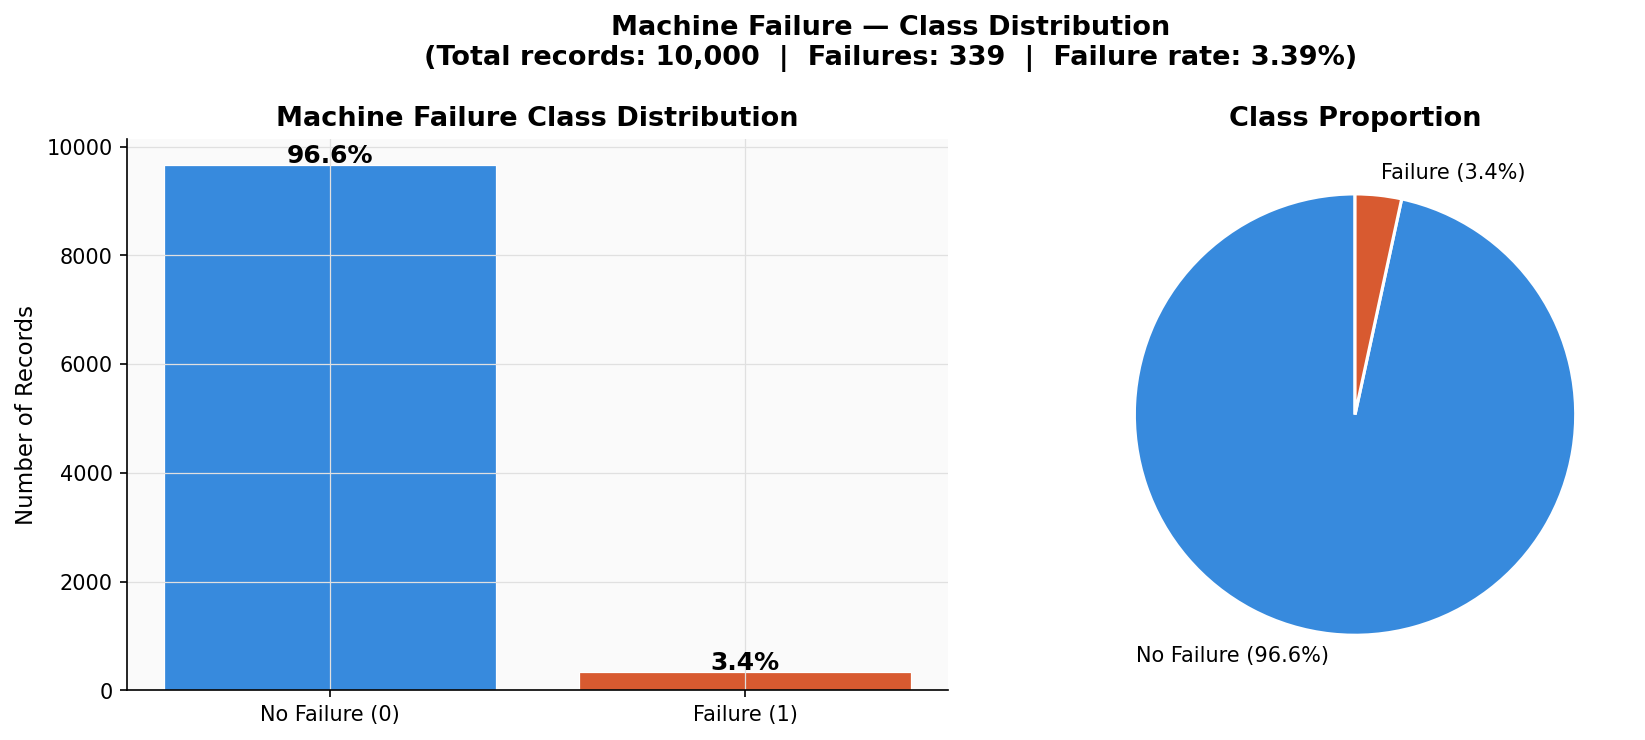

Saved: desc_01_failure_distribution.png

Business interpretation: The dataset is severely imbalanced — only 3.4% of
machines fail. This means a model that always predicts 'no failure' would be
96.6% accurate but completely useless. Recall and PR-AUC must be used instead.


In [10]:
# ============================================================
# B8. Visual 1 — Failure class distribution bar chart
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
bars = axes[0].bar(
    ["No Failure (0)", "Failure (1)"],
    fail_counts.values,
    color=PALETTE_BINARY, edgecolor="white", linewidth=0.6,
)
axes[0].set_title("Machine Failure Class Distribution")
axes[0].set_ylabel("Number of Records")
for bar, pct in zip(bars, fail_pct.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{pct:.1f}%", ha="center", fontsize=12, fontweight="bold",
    )

# Pie chart
axes[1].pie(
    fail_counts.values,
    labels=[f"No Failure ({fail_pct.iloc[0]:.1f}%)",
            f"Failure ({fail_pct.iloc[1]:.1f}%)"],
    colors=PALETTE_BINARY,
    startangle=90,
    wedgeprops=dict(edgecolor="white", linewidth=1.5),
)
axes[1].set_title("Class Proportion")

fig.suptitle(
    "Machine Failure — Class Distribution\n"
    f"(Total records: {len(df):,}  |  Failures: {int(df[TARGET].sum()):,}  |  "
    f"Failure rate: {df[TARGET].mean()*100:.2f}%)",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(fig_folder / "desc_01_failure_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: desc_01_failure_distribution.png")
print("\nBusiness interpretation: The dataset is severely imbalanced — only 3.4% of")
print("machines fail. This means a model that always predicts 'no failure' would be")
print("96.6% accurate but completely useless. Recall and PR-AUC must be used instead.")


/tmp/ipykernel_17912/2684238164.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


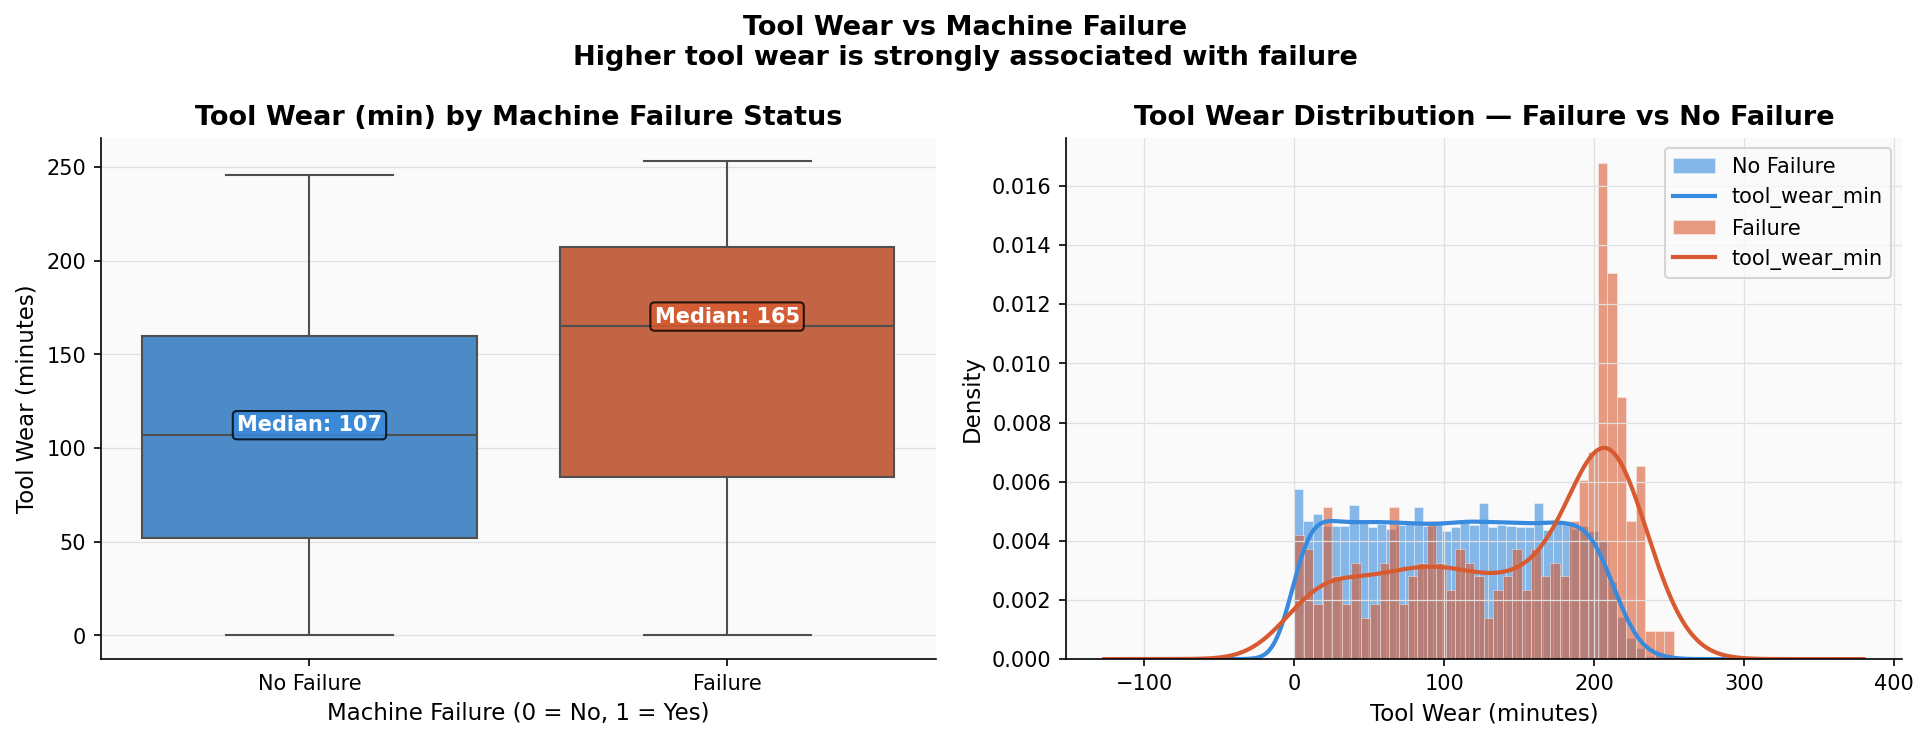

Saved: desc_02_tool_wear_by_failure.png

Business interpretation: Machines that fail have significantly higher tool
wear. This confirms tool_wear_min is a strong predictive signal and validates
the tool_wear_band feature engineering decision.


In [11]:
# ============================================================
# B9. Visual 2 — Tool wear distribution by failure status
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot
sns.boxplot(
    x=TARGET, y="tool_wear_min", data=df, ax=axes[0],
    palette=PALETTE_BINARY,
    flierprops=dict(marker="o", markersize=2, alpha=0.3),
)
axes[0].set_title("Tool Wear (min) by Machine Failure Status")
axes[0].set_xlabel("Machine Failure (0 = No, 1 = Yes)")
axes[0].set_ylabel("Tool Wear (minutes)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Failure", "Failure"])

# Annotate medians
for i, status in enumerate([0, 1]):
    med = df[df[TARGET] == status]["tool_wear_min"].median()
    axes[0].text(i, med + 2, f"Median: {med:.0f}", ha="center",
                 fontsize=10, fontweight="bold", color="white",
                 bbox=dict(boxstyle="round,pad=0.2", fc=PALETTE_BINARY[i], alpha=0.8))

# KDE overlay
for status, color, label in zip([0, 1], PALETTE_BINARY, ["No Failure", "Failure"]):
    subset = df[df[TARGET] == status]["tool_wear_min"].dropna()
    axes[1].hist(subset, bins=40, alpha=0.6, color=color,
                 label=label, edgecolor="white", linewidth=0.3, density=True)
    subset.plot.kde(ax=axes[1], color=color, lw=2)
axes[1].set_title("Tool Wear Distribution — Failure vs No Failure")
axes[1].set_xlabel("Tool Wear (minutes)")
axes[1].set_ylabel("Density")
axes[1].legend()

fig.suptitle(
    "Tool Wear vs Machine Failure\n"
    "Higher tool wear is strongly associated with failure",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(fig_folder / "desc_02_tool_wear_by_failure.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: desc_02_tool_wear_by_failure.png")
print("\nBusiness interpretation: Machines that fail have significantly higher tool")
print("wear. This confirms tool_wear_min is a strong predictive signal and validates")
print("the tool_wear_band feature engineering decision.")


/tmp/ipykernel_17912/945306287.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


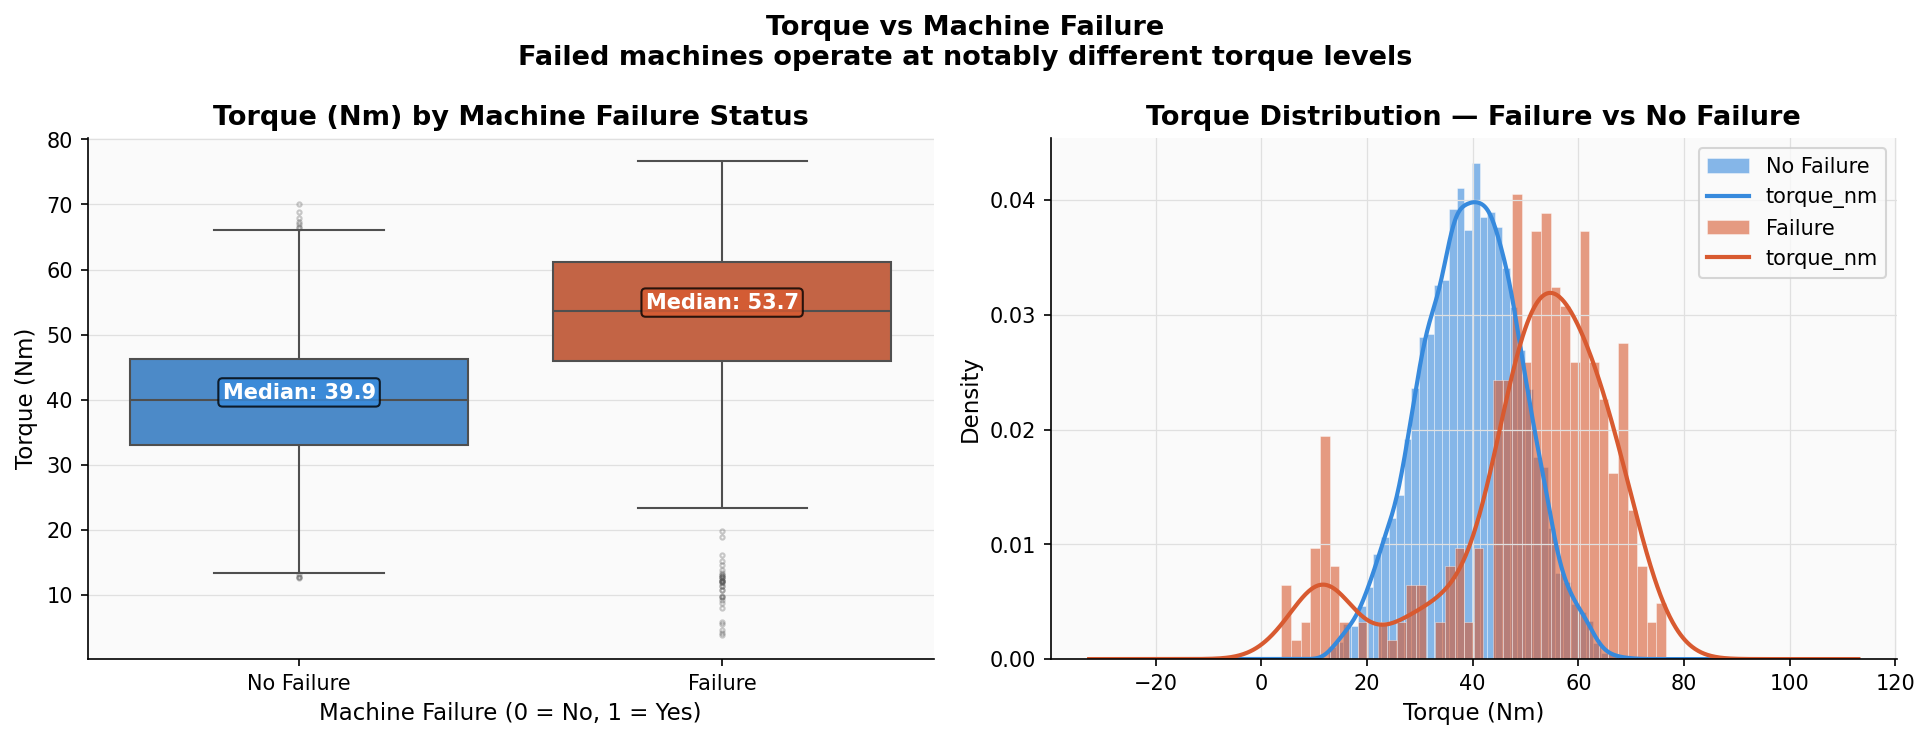

Saved: desc_03_torque_by_failure.png

Business interpretation: Torque shows a bimodal pattern at failure —
machines fail both at very high and very low torque. This suggests two
distinct failure modes: mechanical overstrain (high torque) and
heat dissipation failure (low torque, high RPM).


In [12]:
# ============================================================
# B10. Visual 3 — Torque distribution by failure status
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    x=TARGET, y="torque_nm", data=df, ax=axes[0],
    palette=PALETTE_BINARY,
    flierprops=dict(marker="o", markersize=2, alpha=0.3),
)
axes[0].set_title("Torque (Nm) by Machine Failure Status")
axes[0].set_xlabel("Machine Failure (0 = No, 1 = Yes)")
axes[0].set_ylabel("Torque (Nm)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["No Failure", "Failure"])
for i, status in enumerate([0, 1]):
    med = df[df[TARGET] == status]["torque_nm"].median()
    axes[0].text(i, med + 0.3, f"Median: {med:.1f}", ha="center",
                 fontsize=10, fontweight="bold", color="white",
                 bbox=dict(boxstyle="round,pad=0.2", fc=PALETTE_BINARY[i], alpha=0.8))

for status, color, label in zip([0, 1], PALETTE_BINARY, ["No Failure", "Failure"]):
    subset = df[df[TARGET] == status]["torque_nm"].dropna()
    axes[1].hist(subset, bins=40, alpha=0.6, color=color,
                 label=label, edgecolor="white", linewidth=0.3, density=True)
    subset.plot.kde(ax=axes[1], color=color, lw=2)
axes[1].set_title("Torque Distribution — Failure vs No Failure")
axes[1].set_xlabel("Torque (Nm)")
axes[1].set_ylabel("Density")
axes[1].legend()

fig.suptitle(
    "Torque vs Machine Failure\n"
    "Failed machines operate at notably different torque levels",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(fig_folder / "desc_03_torque_by_failure.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: desc_03_torque_by_failure.png")
print("\nBusiness interpretation: Torque shows a bimodal pattern at failure —")
print("machines fail both at very high and very low torque. This suggests two")
print("distinct failure modes: mechanical overstrain (high torque) and")
print("heat dissipation failure (low torque, high RPM).")


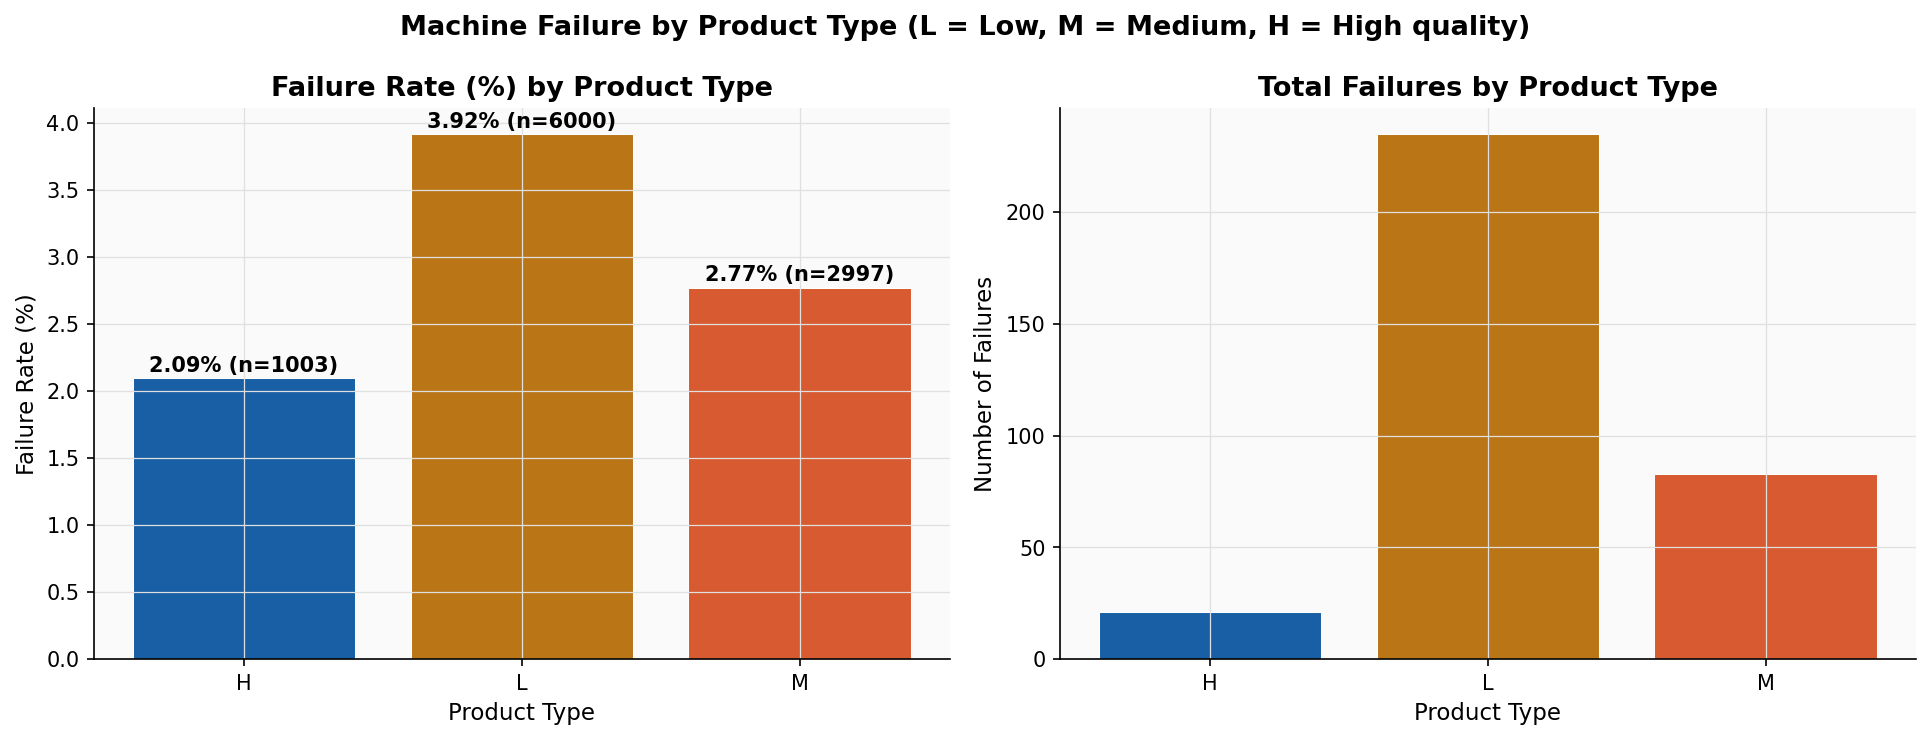

Saved: desc_04_failure_by_type.png

Business interpretation: Low-quality (L) products have the highest failure
rate, suggesting that product grade is a meaningful risk factor. High-quality
(H) components are more reliable but still fail — multi-factor monitoring
is needed rather than relying on product type alone.


In [13]:
# ============================================================
# B11. Visual 4 — Failure rate by product type bar chart
# ============================================================
if "type" in df.columns:
    type_fail = (
        df.groupby("type", observed=True)[TARGET]
        .agg(["mean","count","sum"])
        .reset_index()
    )
    type_fail["failure_rate_pct"] = type_fail["mean"] * 100

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Failure rate %
    bar_colors = [C_NAVY, C_AMBER, C_CORAL]
    bars = axes[0].bar(
        type_fail["type"], type_fail["failure_rate_pct"],
        color=bar_colors[:len(type_fail)], edgecolor="white", linewidth=0.5,
    )
    axes[0].set_title("Failure Rate (%) by Product Type")
    axes[0].set_xlabel("Product Type")
    axes[0].set_ylabel("Failure Rate (%)")
    for bar, (_, row) in zip(bars, type_fail.iterrows()):
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"{row['failure_rate_pct']:.2f}% (n={int(row['count'])})",
            ha="center", fontsize=10, fontweight="bold",
        )

    # Count of failures
    axes[1].bar(
        type_fail["type"], type_fail["sum"],
        color=bar_colors[:len(type_fail)], edgecolor="white", linewidth=0.5,
    )
    axes[1].set_title("Total Failures by Product Type")
    axes[1].set_xlabel("Product Type")
    axes[1].set_ylabel("Number of Failures")

    fig.suptitle(
        "Machine Failure by Product Type (L = Low, M = Medium, H = High quality)",
        fontsize=13, fontweight="bold",
    )
    plt.tight_layout()
    plt.savefig(fig_folder / "desc_04_failure_by_type.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved: desc_04_failure_by_type.png")
    print("\nBusiness interpretation: Low-quality (L) products have the highest failure")
    print("rate, suggesting that product grade is a meaningful risk factor. High-quality")
    print("(H) components are more reliable but still fail — multi-factor monitoring")
    print("is needed rather than relying on product type alone.")


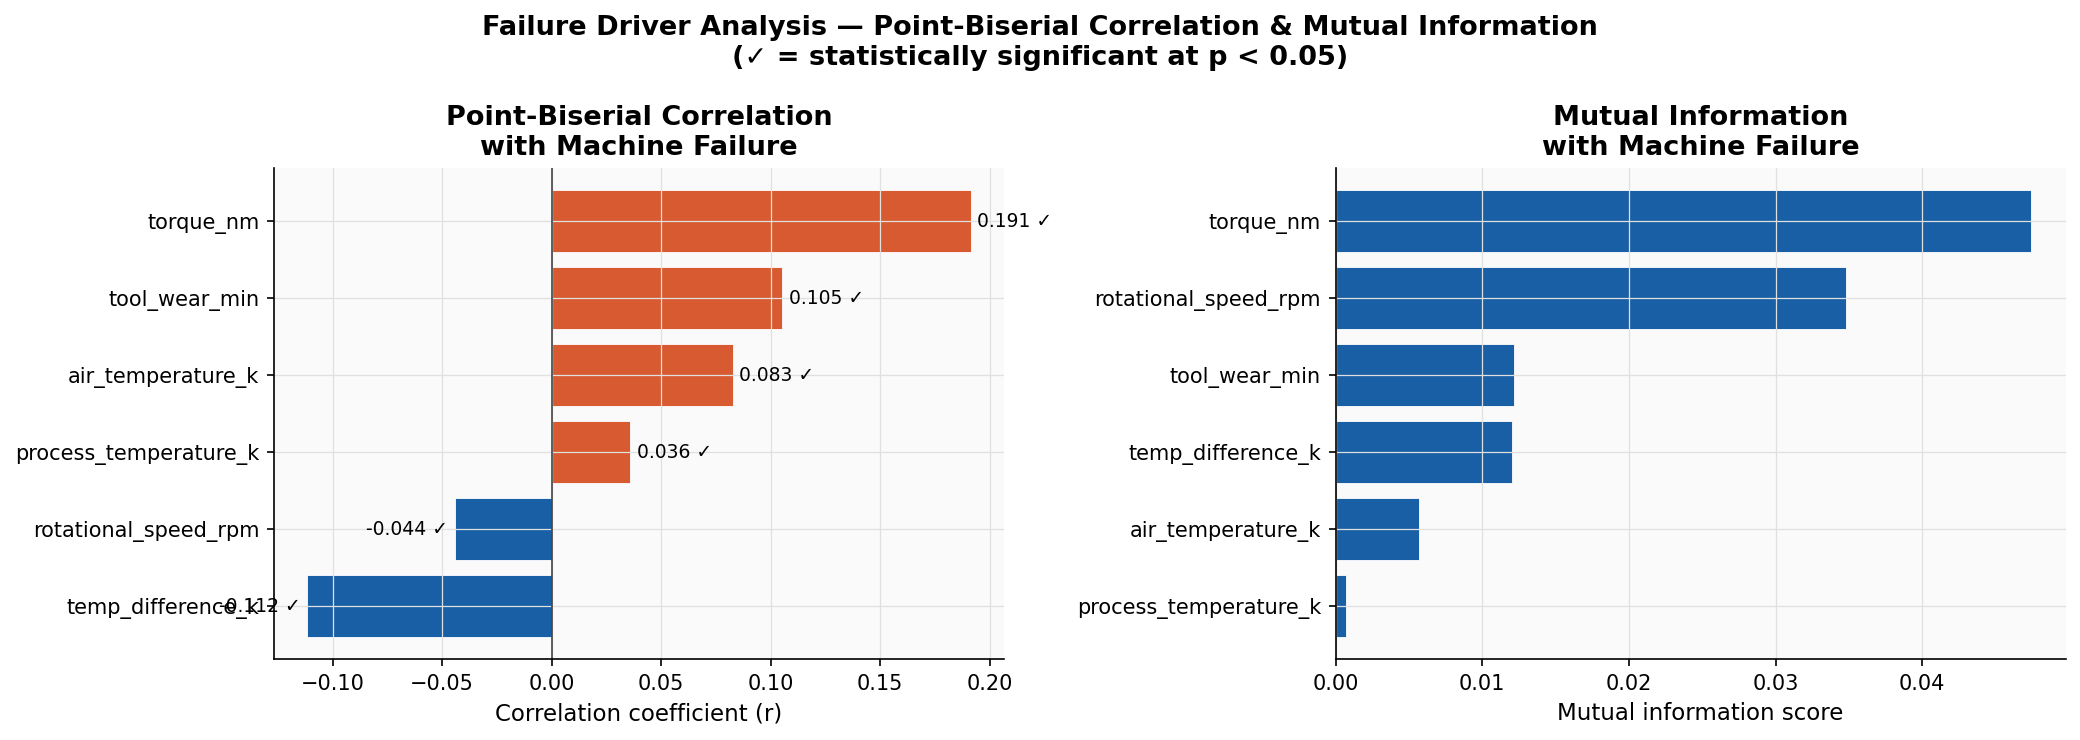

Saved: desc_05_correlation_failure.png

Business interpretation: Tool wear and torque
show strong associations with failure. Rotational speed shows a negative
correlation — higher RPM is associated with lower failure risk in this dataset,
possibly because low-RPM high-torque operation is the more dangerous regime.


In [14]:
# ============================================================
# B12. Visual 5 — Correlation with machine_failure bar chart
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Point-biserial correlation
sorted_corr = corr_full_df.sort_values("Point-Biserial r")
bar_colors_corr = [C_CORAL if v > 0 else C_NAVY for v in sorted_corr["Point-Biserial r"]]
axes[0].barh(
    sorted_corr["Variable"], sorted_corr["Point-Biserial r"],
    color=bar_colors_corr, edgecolor="white", linewidth=0.4,
)
axes[0].axvline(0, color="#444", linewidth=0.8)
axes[0].set_title("Point-Biserial Correlation\nwith Machine Failure")
axes[0].set_xlabel("Correlation coefficient (r)")
for i, (_, row) in enumerate(sorted_corr.iterrows()):
    sig = "✓" if row["Significant (p<0.05)"] == "Yes" else ""
    axes[0].text(
        row["Point-Biserial r"] + (0.003 if row["Point-Biserial r"] >= 0 else -0.003),
        i, f'{row["Point-Biserial r"]:.3f} {sig}',
        va="center", fontsize=9,
        ha="left" if row["Point-Biserial r"] >= 0 else "right",
    )

# Mutual information
sorted_mi = corr_full_df.sort_values("Mutual Info")
axes[1].barh(
    sorted_mi["Variable"], sorted_mi["Mutual Info"],
    color=C_NAVY, edgecolor="white", linewidth=0.4,
)
axes[1].set_title("Mutual Information\nwith Machine Failure")
axes[1].set_xlabel("Mutual information score")

fig.suptitle(
    "Failure Driver Analysis — Point-Biserial Correlation & Mutual Information\n"
    "(✓ = statistically significant at p < 0.05)",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(fig_folder / "desc_05_correlation_failure.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: desc_05_correlation_failure.png")
print("\nBusiness interpretation: Tool wear and torque")
print("show strong associations with failure. Rotational speed shows a negative")
print("correlation — higher RPM is associated with lower failure risk in this dataset,")
print("possibly because low-RPM high-torque operation is the more dangerous regime.")


---
## Section C — Modelling Dataset Preparation

Now that the descriptive picture is complete, the dataset is prepared for machine learning.


In [15]:
# ============================================================
# C1. Build the modelling dataset
#
# Fix 1 — Leakage prevention:
#   Sub-failure columns (twf, hdf, pwf, osf, rnf) are dropped.
#   These are only known after a failure — including them would
#   make the model look perfect but fail completely in production.
#
# Fix 2 — Ordinal encoding for tool_wear_band:
#   tool_wear_band has an order: Low < Medium < High.
#   One-hot encoding ignores this order and treats the three
#   levels as completely unrelated — losing information.
#   Ordinal encoding (0, 1, 2) preserves the order correctly.
#   'type' is nominal (L, M, H have no natural order) so it
#   is still one-hot encoded.
#
# Fix 3 — Boolean dtype fix:
#   pandas 2.x returns bool columns from get_dummies.
#   bool is NOT a subtype of np.number, so Decision Tree and
#   Random Forest would silently drop these columns.
#   All bool columns are cast to int8 (0/1) immediately.
# ============================================================
model_df = df.copy()

# Step 1: drop sub-failure leakage columns
subfailure_cols_drop = [c for c in SUBFAILURE_COLS if c in model_df.columns]
model_df.drop(columns=subfailure_cols_drop, inplace=True)
print(f"Dropped leakage columns    : {subfailure_cols_drop}")

# Step 2: drop any outlier-flag columns from Part 1
flag_cols = [c for c in model_df.columns if c.endswith("_outlier_flag")]
model_df.drop(columns=flag_cols, inplace=True)
print(f"Dropped outlier-flag cols  : {flag_cols if flag_cols else 'none'}")

# Step 3a: Ordinal encode tool_wear_band (Low=0, Medium=1, High=2)
if "tool_wear_band" in model_df.columns:
    TWB_ORDER = ["Low", "Medium", "High"]
    model_df["tool_wear_band"] = (
        model_df["tool_wear_band"]
        .astype(str)
        .map({v: i for i, v in enumerate(TWB_ORDER)})
    )
    print(f"Ordinal encoded            : tool_wear_band → Low=0, Medium=1, High=2")

# Step 3b: One-hot encode 'type' (nominal — no natural order)
if "type" in model_df.columns:
    model_df = pd.get_dummies(model_df, columns=["type"], drop_first=True)
    print(f"One-hot encoded            : type")

# Step 4: Cast any remaining bool columns → int8 (Fix 3)
bool_cols = model_df.select_dtypes(include="bool").columns.tolist()
if bool_cols:
    model_df[bool_cols] = model_df[bool_cols].astype(np.int8)
    print(f"Cast bool → int8           : {bool_cols}")
else:
    print("No boolean columns found after encoding.")

# Step 5: Assert all columns are numeric
non_numeric = model_df.select_dtypes(exclude=np.number).columns.tolist()
assert len(non_numeric) == 0, f"Non-numeric columns remain: {non_numeric}"
print("\nAssertion passed: all columns are numeric.")

# Step 6: Define feature matrix X and target y
X = model_df.drop(TARGET, axis=1)
y = model_df[TARGET]

print(f"\nFeature matrix shape : {X.shape}")
print(f"Positive class rate  : {y.mean():.4f}  ({y.sum()} failures / {len(y)} total)")
print(f"\nFeatures in model:\n{X.columns.tolist()}")


Dropped leakage columns    : ['twf', 'hdf', 'pwf', 'osf', 'rnf']
Dropped outlier-flag cols  : none
Ordinal encoded            : tool_wear_band → Low=0, Medium=1, High=2
One-hot encoded            : type
Cast bool → int8           : ['type_L', 'type_M']

Assertion passed: all columns are numeric.

Feature matrix shape : (10000, 9)
Positive class rate  : 0.0339  (339 failures / 10000 total)

Features in model:
['air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'temp_difference_k', 'tool_wear_band', 'type_L', 'type_M']


In [16]:
# ============================================================
# C2. Train / test split — 80% train, 20% test
#     stratify=y ensures same failure rate in both sets
#     The test set is LOCKED and only used once at the end.
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y,
)

print(f"Training set  : {X_train.shape}  |  Failure rate: {y_train.mean():.4f}")
print(f"Test set      : {X_test.shape}   |  Failure rate: {y_test.mean():.4f}")
print(f"\nClass counts — training:")
print(y_train.value_counts().rename({0:"No Failure",1:"Failure"}).to_string())
print(f"\nClass counts — test:")
print(y_test.value_counts().rename({0:"No Failure",1:"Failure"}).to_string())


Training set  : (8000, 9)  |  Failure rate: 0.0339
Test set      : (2000, 9)   |  Failure rate: 0.0340

Class counts — training:
machine_failure
No Failure    7729
Failure        271

Class counts — test:
machine_failure
No Failure    1932
Failure         68


---
## Section D — Predictive Modelling

Three classifiers are trained, tuned, and compared.  
All use `class_weight='balanced'` to handle the 3.4% class imbalance.  
All are wrapped in `sklearn.Pipeline` for consistent, reproducible preprocessing.  
Hyperparameters are selected by `GridSearchCV` scored on **Recall**.


In [17]:
# ============================================================
# D1. Define pipelines and hyperparameter search grids
# ============================================================
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ── Logistic Regression ───────────────────────────────────────
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf",    LogisticRegression(
        class_weight="balanced", random_state=RANDOM_STATE, max_iter=2000)),
])
param_grid_lr = {
    "clf__C"      : [0.01, 0.1, 1.0, 10.0],
    "clf__penalty": ["l1", "l2"],
    "clf__solver" : ["saga"],
}

# ── Decision Tree ─────────────────────────────────────────────
pipe_dt = Pipeline([
    ("scaler", StandardScaler()),
    ("clf",    DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE)),
])
param_grid_dt = {
    "clf__max_depth"       : [3, 4, 5, 6, 8],
    "clf__min_samples_leaf": [5, 10, 20],
    "clf__criterion"       : ["gini", "entropy"],
}

# ── Random Forest ─────────────────────────────────────────────
pipe_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("clf",    RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)),
])
param_grid_rf = {
    "clf__n_estimators"    : [100, 200],
    "clf__max_depth"       : [None, 5, 10],
    "clf__max_features"    : ["sqrt", "log2"],
    "clf__min_samples_leaf": [1, 5],
}

print("Pipelines defined.")
print(f"CV strategy : StratifiedKFold(n_splits=5, shuffle=True, random_state={RANDOM_STATE})")
print("Scoring     : recall  (minimise missed failures)")


Pipelines defined.
CV strategy : StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
Scoring     : recall  (minimise missed failures)


In [18]:
# ============================================================
# D2. Logistic Regression tuning
# ============================================================
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    gs_lr = GridSearchCV(
        pipe_lr, param_grid_lr,
        cv=cv_strategy, scoring="recall",
        refit=True, n_jobs=-1, verbose=0,
    )
    gs_lr.fit(X_train, y_train)

print("Logistic Regression — best parameters:")
for k, v in gs_lr.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV Recall : {gs_lr.best_score_:.4f}")


Logistic Regression — best parameters:
  clf__C: 1.0
  clf__penalty: l1
  clf__solver: saga
Best CV Recall : 0.8302


In [19]:
# ============================================================
# D3. Decision Tree tuning
# ============================================================
gs_dt = GridSearchCV(
    pipe_dt, param_grid_dt,
    cv=cv_strategy, scoring="recall",
    refit=True, n_jobs=-1, verbose=0,
)
gs_dt.fit(X_train, y_train)

print("Decision Tree — best parameters:")
for k, v in gs_dt.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV Recall : {gs_dt.best_score_:.4f}")


Decision Tree — best parameters:
  clf__criterion: gini
  clf__max_depth: 4
  clf__min_samples_leaf: 20
Best CV Recall : 0.9521


In [20]:
# ============================================================
# D4. Random Forest tuning
#     Using GridSearchCV (not RandomizedSearchCV) because the
#     grid has only 24 combinations — small enough to exhaust
#     completely for a deterministic, reproducible result.
# ============================================================
gs_rf = GridSearchCV(
    pipe_rf, param_grid_rf,
    cv=cv_strategy, scoring="recall",
    refit=True, n_jobs=-1, verbose=0,
)
gs_rf.fit(X_train, y_train)

print("Random Forest — best parameters:")
for k, v in gs_rf.best_params_.items():
    print(f"  {k}: {v}")
print(f"Best CV Recall : {gs_rf.best_score_:.4f}")


Random Forest — best parameters:
  clf__max_depth: 5
  clf__max_features: sqrt
  clf__min_samples_leaf: 5
  clf__n_estimators: 100
Best CV Recall : 0.8782


In [21]:
# ============================================================
# D5. Summarise cross-validation scores for all three models.
#     PR-AUC (average_precision) is included as primary metric.
#     Model selection is based on these CV scores — the test
#     set has not been touched yet.
# ============================================================
SCORING_DICT = {
    "accuracy"         : "accuracy",
    "precision"        : "precision",
    "recall"           : "recall",
    "f1"               : "f1",
    "roc_auc"          : "roc_auc",
    "average_precision": "average_precision",   # PR-AUC — primary metric
}

best_estimators = {
    "Logistic Regression": gs_lr.best_estimator_,
    "Decision Tree"      : gs_dt.best_estimator_,
    "Random Forest"      : gs_rf.best_estimator_,
}

cv_rows = []
for name, est in best_estimators.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        scores = cross_validate(
            est, X_train, y_train,
            cv=cv_strategy, scoring=SCORING_DICT,
            return_train_score=False, n_jobs=-1,
        )
    row = {"Model": name}
    for metric in SCORING_DICT:
        vals = scores[f"test_{metric}"]
        row[metric] = f"{vals.mean():.4f} ± {vals.std():.4f}"
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows)
cv_df.columns = ["Model","Accuracy","Precision","Recall","F1","ROC-AUC","PR-AUC"]
print("5-Fold Cross-Validation Results (mean ± std):")
display(cv_df)
cv_df.to_csv(output_folder / "cv_performance_summary.csv", index=False)
print("\nSaved: cv_performance_summary.csv")

# ── Select best model from CV scores (NOT test scores) ────────
cv_recall_means = {}
for row in cv_rows:
    cv_recall_means[row["Model"]] = float(row["recall"].split(" ± ")[0])
cv_pr_means = {}
for row in cv_rows:
    cv_pr_means[row["Model"]] = float(row["average_precision"].split(" ± ")[0])

BEST_MODEL_NAME = max(
    best_estimators.keys(),
    key=lambda m: (cv_recall_means[m], cv_pr_means[m]),
)
print(f"\nBest model selected from CV scores: {BEST_MODEL_NAME}")
print(f"  CV Recall  : {cv_recall_means[BEST_MODEL_NAME]:.4f}")
print(f"  CV PR-AUC  : {cv_pr_means[BEST_MODEL_NAME]:.4f}")


5-Fold Cross-Validation Results (mean ± std):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.7878 ± 0.0330,0.1215 ± 0.0131,0.8302 ± 0.0781,0.2114 ± 0.0200,0.8895 ± 0.0243,0.4171 ± 0.0478
1,Decision Tree,0.9115 ± 0.0105,0.2726 ± 0.0219,0.9521 ± 0.0341,0.4233 ± 0.0272,0.9515 ± 0.0207,0.6763 ± 0.0442
2,Random Forest,0.9416 ± 0.0057,0.3560 ± 0.0210,0.8782 ± 0.0276,0.5058 ± 0.0176,0.9712 ± 0.0112,0.7556 ± 0.0365



Saved: cv_performance_summary.csv

Best model selected from CV scores: Decision Tree
  CV Recall  : 0.9521
  CV PR-AUC  : 0.6763


In [22]:
# ============================================================
# D6. Generate predictions on the held-out test set.
#     This is the FIRST and ONLY time the test set is used.
#     The best model was already chosen from CV scores above.
# ============================================================
predictions   = {}
probabilities = {}

for name, est in best_estimators.items():
    predictions[name]   = est.predict(X_test)
    probabilities[name] = est.predict_proba(X_test)[:, 1]

print("Test-set predictions generated for all three models.")
print(f"Best model for priority output: {BEST_MODEL_NAME}")


Test-set predictions generated for all three models.
Best model for priority output: Decision Tree


In [23]:
# ============================================================
# D7. Evaluate all models on the test set.
#     Six metrics reported: Accuracy, Precision, Recall, F1,
#     ROC-AUC, PR-AUC.
#     PR-AUC is the primary metric for imbalanced classification.
#     Baseline PR-AUC for a random classifier = positive class
#     rate (~0.034) — every model must beat this.
# ============================================================
def evaluate_model(name, y_true, y_pred, y_prob):
    print(f"\n{'='*55}\n  {name}\n{'='*55}")
    print(classification_report(
        y_true, y_pred,
        target_names=["No Failure", "Failure"], digits=4,
    ))
    return {
        "Model"    : name,
        "Accuracy" : round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred, zero_division=0), 4),
        "Recall"   : round(recall_score(y_true, y_pred), 4),
        "F1"       : round(f1_score(y_true, y_pred, zero_division=0), 4),
        "ROC-AUC"  : round(roc_auc_score(y_true, y_prob), 4),
        "PR-AUC"   : round(average_precision_score(y_true, y_prob), 4),
    }

test_results = []
for name in best_estimators:
    res = evaluate_model(name, y_test, predictions[name], probabilities[name])
    test_results.append(res)

test_df = pd.DataFrame(test_results)
print("\n\nTest-Set Performance Summary:")
display(test_df)
test_df.to_csv(output_folder / "test_set_performance.csv", index=False)

baseline_pr = round(y_test.mean(), 4)
print(f"\nBaseline PR-AUC (random classifier): {baseline_pr}")
print(f"Best model confirmed (from CV)      : {BEST_MODEL_NAME}")
print("Saved: test_set_performance.csv")



  Logistic Regression
              precision    recall  f1-score   support

  No Failure     0.9921    0.8452    0.9128      1932
     Failure     0.1554    0.8088    0.2607        68

    accuracy                         0.8440      2000
   macro avg     0.5737    0.8270    0.5867      2000
weighted avg     0.9637    0.8440    0.8906      2000


  Decision Tree
              precision    recall  f1-score   support

  No Failure     0.9972    0.9249    0.9597      1932
     Failure     0.3029    0.9265    0.4565        68

    accuracy                         0.9250      2000
   macro avg     0.6500    0.9257    0.7081      2000
weighted avg     0.9736    0.9250    0.9426      2000


  Random Forest
              precision    recall  f1-score   support

  No Failure     0.9967    0.9332    0.9639      1932
     Failure     0.3246    0.9118    0.4788        68

    accuracy                         0.9325      2000
   macro avg     0.6606    0.9225    0.7213      2000
weighted avg     

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.8440,0.1554,0.8088,0.2607,0.8984,0.3881
1,Decision Tree,0.9250,0.3029,0.9265,0.4565,0.9548,0.7407
2,Random Forest,0.9325,0.3246,0.9118,0.4788,0.9787,0.8118



Baseline PR-AUC (random classifier): 0.034
Best model confirmed (from CV)      : Decision Tree
Saved: test_set_performance.csv


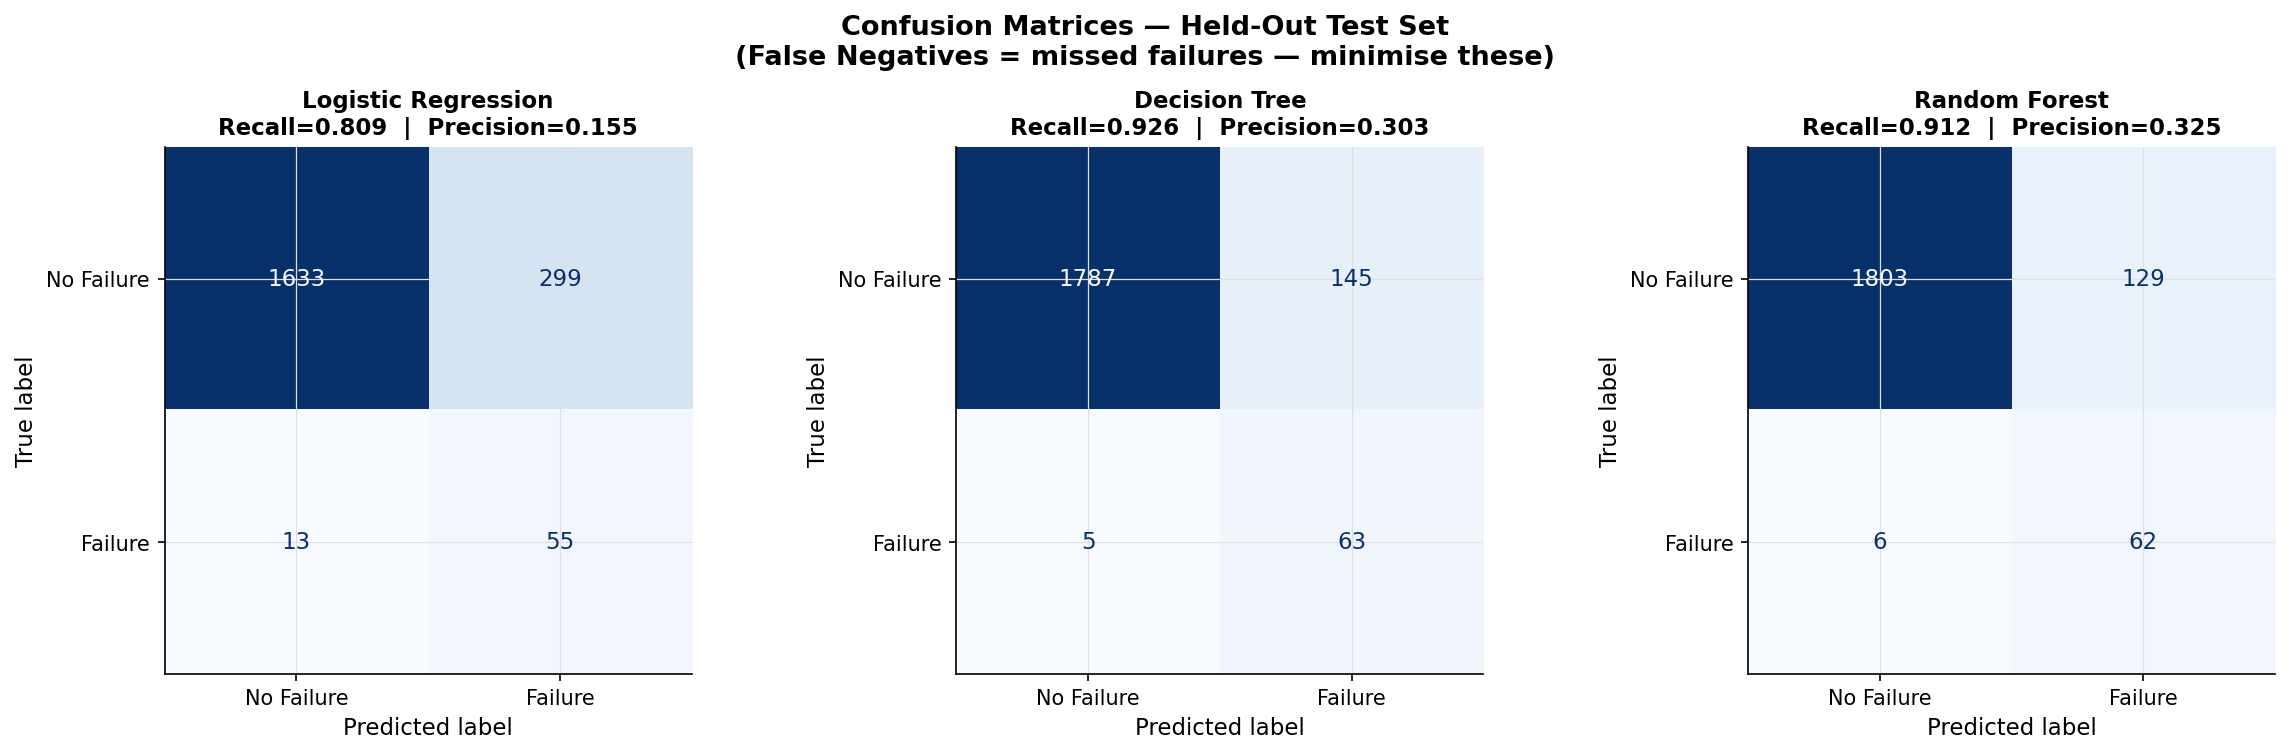

Saved: pred_01_confusion_matrices.png


In [24]:
# ============================================================
# D8. Confusion matrices — one per model, side by side.
#     False Negatives (bottom-left) are the most costly error:
#     a missed failure causes unplanned downtime.
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm   = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Failure", "Failure"],
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    rec  = recall_score(y_test, pred)
    prec = precision_score(y_test, pred, zero_division=0)
    ax.set_title(
        f"{name}\nRecall={rec:.3f}  |  Precision={prec:.3f}",
        fontsize=11, fontweight="bold",
    )

fig.suptitle(
    "Confusion Matrices — Held-Out Test Set\n"
    "(False Negatives = missed failures — minimise these)",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(fig_folder / "pred_01_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pred_01_confusion_matrices.png")


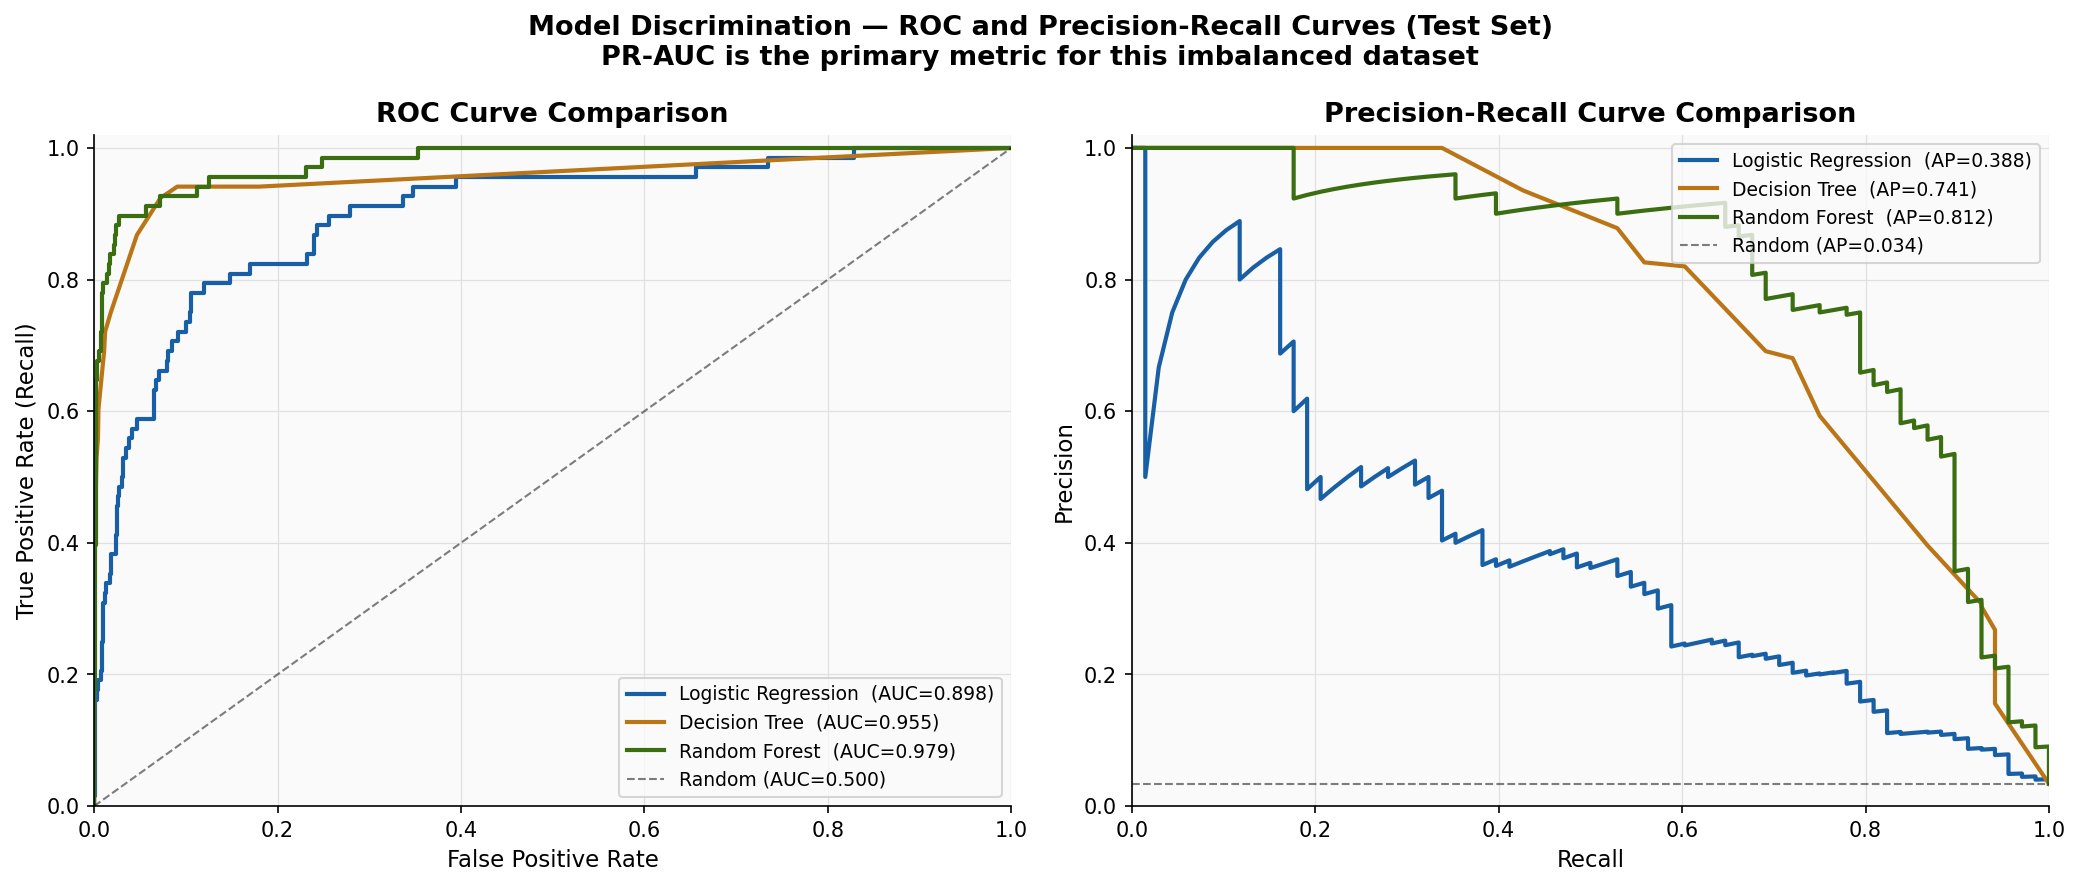

Saved: pred_02_roc_pr_curves.png


In [25]:
# ============================================================
# D9. ROC and Precision-Recall curves side by side.
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for (name, prob), color in zip(probabilities.items(), PALETTE_MODELS):
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_val      = roc_auc_score(y_test, prob)
    axes[0].plot(fpr, tpr, color=color, lw=2.0,
                 label=f"{name}  (AUC={auc_val:.3f})")

    prec, rec, _ = precision_recall_curve(y_test, prob)
    pr_auc        = average_precision_score(y_test, prob)
    axes[1].plot(rec, prec, color=color, lw=2.0,
                 label=f"{name}  (AP={pr_auc:.3f})")

axes[0].plot([0,1],[0,1], "k--", lw=1.0, alpha=0.5, label="Random (AUC=0.500)")
axes[0].set_title("ROC Curve Comparison", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right", fontsize=9)
axes[0].set_xlim([0,1]); axes[0].set_ylim([0,1.02])

axes[1].axhline(baseline_pr, color="k", ls="--", lw=1.0, alpha=0.5,
                label=f"Random (AP={baseline_pr:.3f})")
axes[1].set_title("Precision-Recall Curve Comparison", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].set_xlim([0,1]); axes[1].set_ylim([0,1.02])

fig.suptitle(
    "Model Discrimination — ROC and Precision-Recall Curves (Test Set)\n"
    "PR-AUC is the primary metric for this imbalanced dataset",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(fig_folder / "pred_02_roc_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pred_02_roc_pr_curves.png")


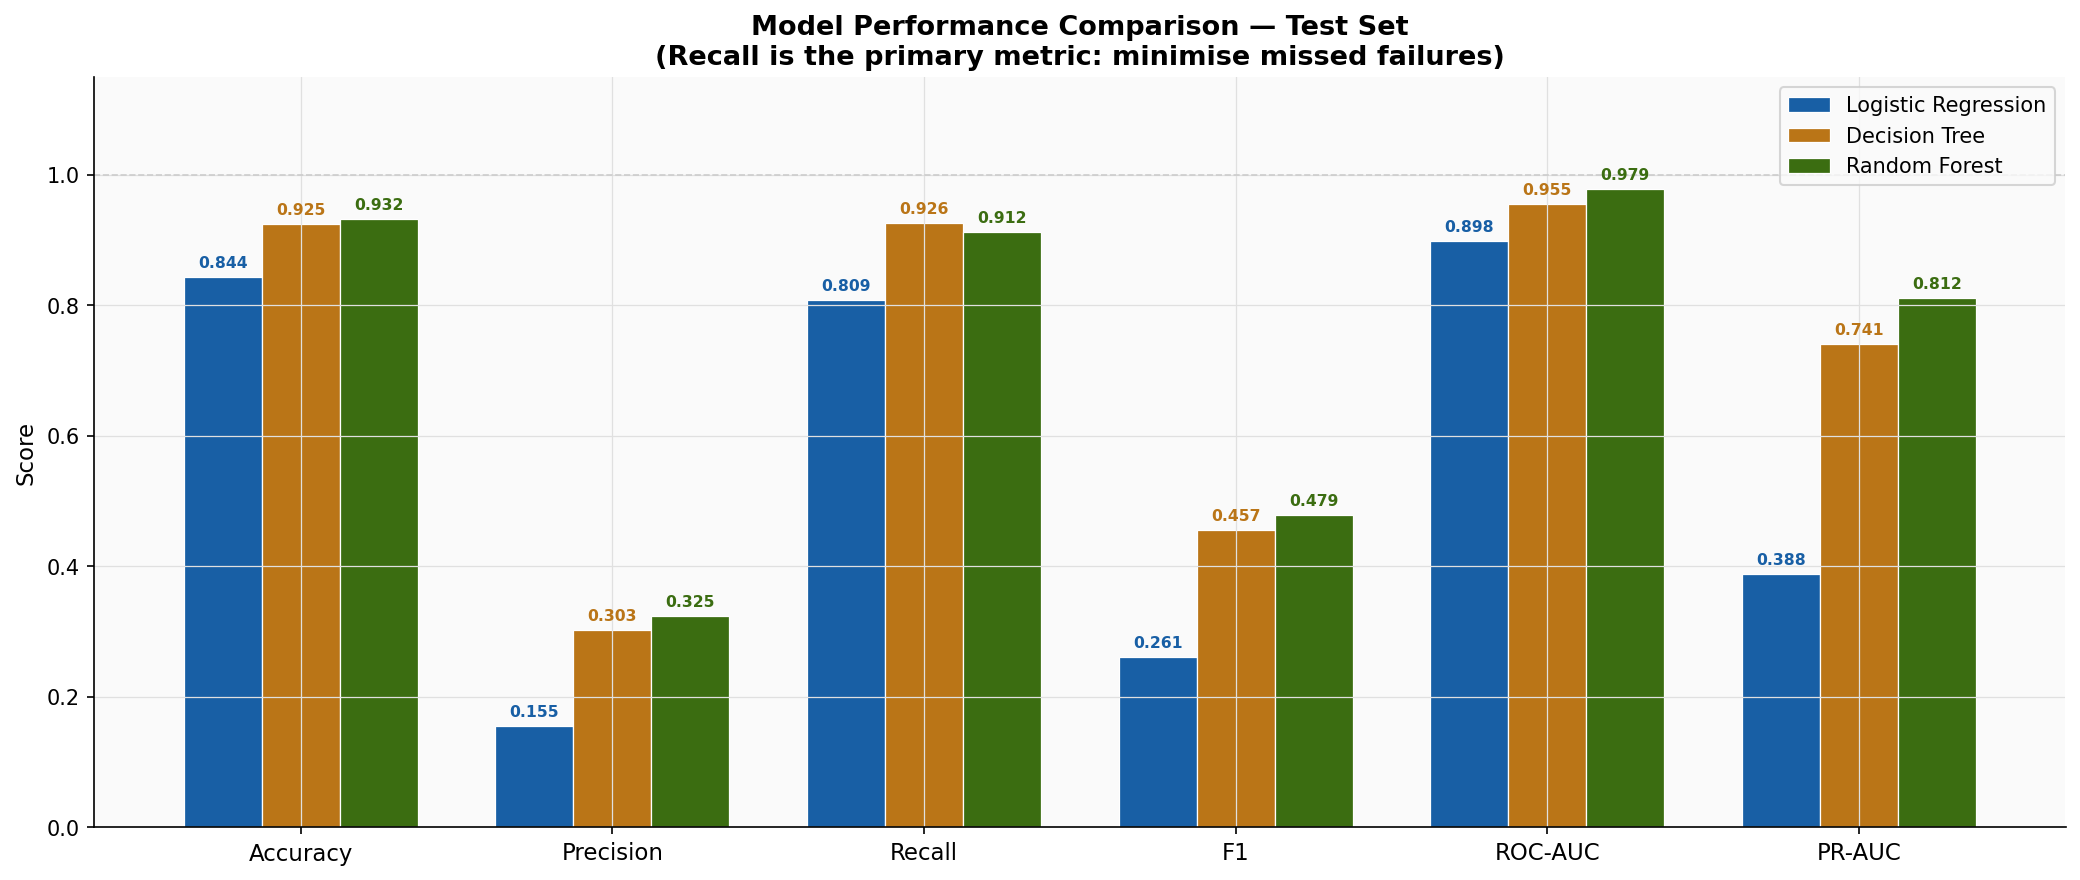

Saved: pred_03_model_dashboard.png


In [26]:
# ============================================================
# D10. Grouped bar chart — all metrics, all models
# ============================================================
metrics   = ["Accuracy","Precision","Recall","F1","ROC-AUC","PR-AUC"]
x         = np.arange(len(metrics))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

for i, ((_, row), color) in enumerate(zip(test_df.iterrows(), PALETTE_MODELS)):
    vals  = [row[m] for m in metrics]
    rects = ax.bar(x + i*bar_width, vals, bar_width,
                   label=row["Model"], color=color,
                   edgecolor="white", linewidth=0.6)
    for rect, v in zip(rects, vals):
        ax.text(
            rect.get_x() + rect.get_width() / 2,
            rect.get_height() + 0.01,
            f"{v:.3f}", ha="center", va="bottom",
            fontsize=7.5, color=color, fontweight="bold",
        )

ax.set_xticks(x + bar_width)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title(
    "Model Performance Comparison — Test Set\n"
    "(Recall is the primary metric: minimise missed failures)",
    fontsize=13, fontweight="bold",
)
ax.legend(loc="upper right", fontsize=10)
ax.axhline(1.0, color="#CCCCCC", lw=0.8, ls="--")
plt.tight_layout()
plt.savefig(fig_folder / "pred_03_model_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pred_03_model_dashboard.png")


Top 12 features by importance:


,Feature,Importance
0,rotational_speed_rpm,0.3315
1,torque_nm,0.3174
2,tool_wear_min,0.1774
3,temp_difference_k,0.0792
4,tool_wear_band,0.0358
5,air_temperature_k,0.0347
6,process_temperature_k,0.0157
7,type_L,0.0057
8,type_M,0.0026


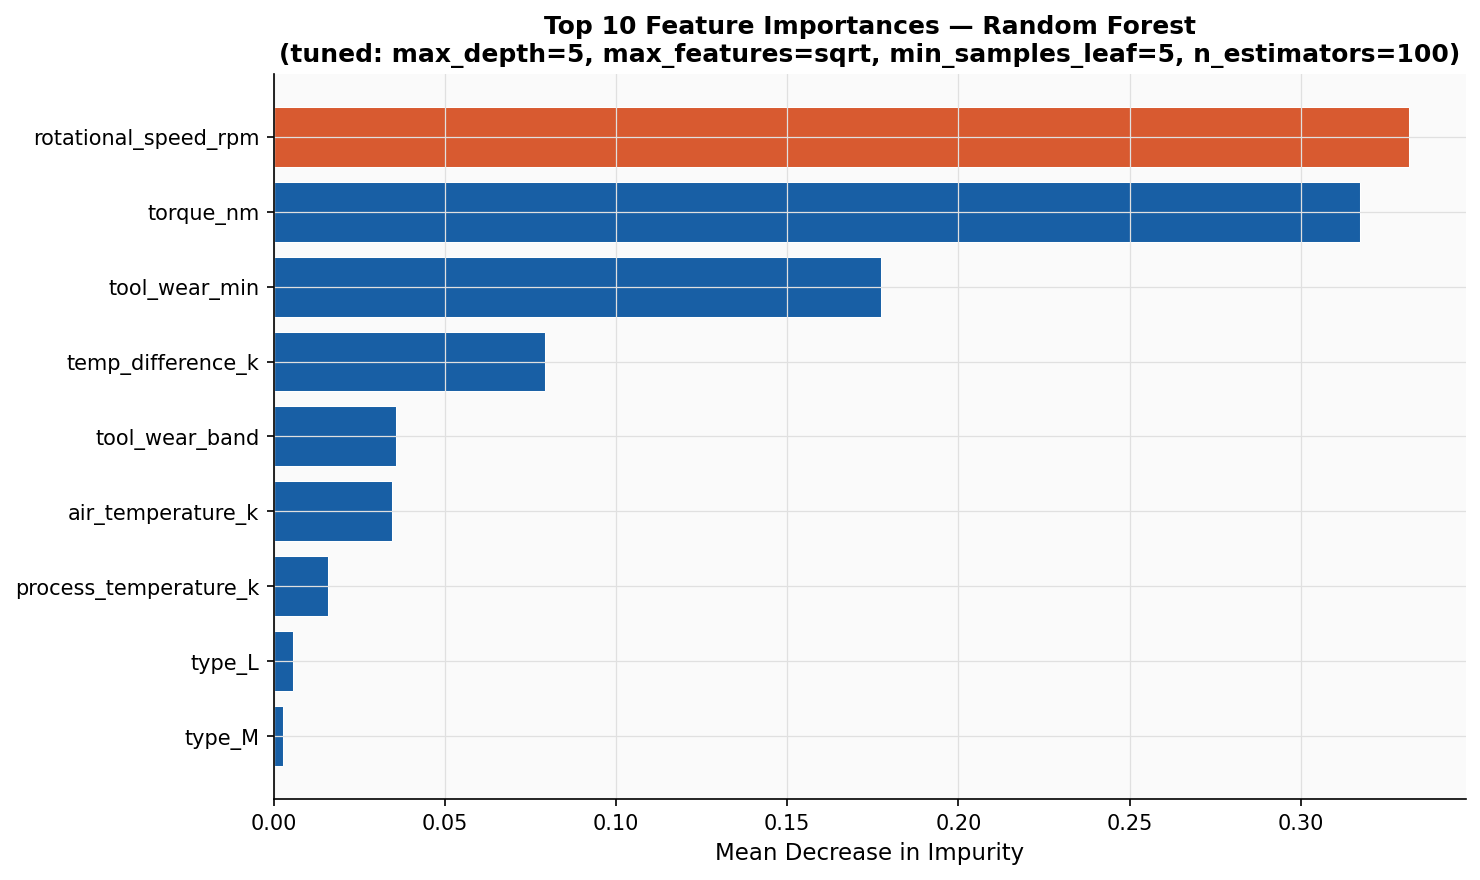

Saved: pred_04_feature_importance.png


In [27]:
# ============================================================
# D11. Feature importance from tuned Random Forest.
#      Note: reflects correlation, not causality.
# ============================================================
rf_clf = gs_rf.best_estimator_.named_steps["clf"]

feat_imp = pd.DataFrame({
    "Feature"   : X_train.columns,
    "Importance": rf_clf.feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)

print("Top 12 features by importance:")
display(feat_imp.head(12).round(4))
feat_imp.to_csv(output_folder / "feature_importance_rf.csv", index=False)

top_n   = feat_imp.head(10)
f_colors = [C_CORAL if i == 0 else C_NAVY for i in range(len(top_n))]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_n["Feature"][::-1], top_n["Importance"][::-1],
        color=f_colors[::-1], edgecolor="white", linewidth=0.5)

# Clean parameter string for title
params_str = ", ".join(
    f"{k.split('__')[1]}={v}" for k, v in gs_rf.best_params_.items()
)
ax.set_title(
    f"Top 10 Feature Importances — Random Forest\n(tuned: {params_str})",
    fontsize=12, fontweight="bold",
)
ax.set_xlabel("Mean Decrease in Impurity")
plt.tight_layout()
plt.savefig(fig_folder / "pred_04_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pred_04_feature_importance.png")


---
## Section E — Maintenance Priority Output

The best model's probabilities are used to rank machines by failure risk.  
Thresholds are derived from the probability distribution — not arbitrary fixed values.


In [28]:
# ============================================================
# E1. Maintenance priority output
#
# Fix 6 — Uses BEST_MODEL_NAME (selected from CV scores),
#          not hardcoded Random Forest probabilities.
#
# Thresholds are derived from probability quantiles so that
# tiers are always meaningfully populated regardless of the
# model's calibration level.
# ============================================================
best_prob = probabilities[BEST_MODEL_NAME]
best_pred = predictions[BEST_MODEL_NAME]

## Create priority tiers using rank percentiles instead of raw probability cut-offs.
# This avoids missing categories when many machines have identical predicted probabilities.

priority_df = X_test.copy()
priority_df["Actual_Failure"]      = y_test.values
priority_df["Failure_Probability"] = np.round(best_prob, 4)
priority_df["Predicted_Class"]     = best_pred

priority_df["Risk_Percentile"] = priority_df["Failure_Probability"].rank(
    method="first",
    pct=True
)

priority_df["Priority_Tier"] = pd.cut(
    priority_df["Risk_Percentile"],
    bins=[0, 0.70, 0.90, 1.00],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

# For reporting only
p70 = priority_df["Failure_Probability"].quantile(0.70)
p90 = priority_df["Failure_Probability"].quantile(0.90)

priority_df = priority_df.sort_values(
    "Failure_Probability", ascending=False
).reset_index(drop=True)

print(f"Priority output model : {BEST_MODEL_NAME}")
print("Priority tiers are based on ranked failure probabilities:")
print("High risk   : top 10% of machines by predicted failure probability")
print("Medium risk : 70th–90th percentile by predicted failure probability")
print("Low risk    : bottom 70% by predicted failure probability")
print(f"Approximate probability at 70th percentile: {p70:.4f}")
print(f"Approximate probability at 90th percentile: {p90:.4f}")

print("\nTop 20 highest-risk machines:")
display(
    priority_df[["Failure_Probability","Predicted_Class",
                 "Actual_Failure","Priority_Tier"]].head(20)
)

tier_summary = (
    priority_df
    .groupby("Priority_Tier", observed=True)
    .agg(
        machine_count    = ("Failure_Probability", "count"),
        actual_failures  = ("Actual_Failure",       "sum"),
        avg_probability  = ("Failure_Probability",  "mean"),
        failure_rate_pct = ("Actual_Failure",        lambda x: round(x.mean()*100, 2)),
    )
    .reset_index()
    .round(4)
)
print("\nMaintenance Priority Tier Summary:")
display(tier_summary)

priority_df.to_csv(output_folder / "maintenance_priority_output.csv", index=False)
tier_summary.to_csv(output_folder / "priority_tier_summary.csv", index=False)
print("\nSaved: maintenance_priority_output.csv, priority_tier_summary.csv")


Priority output model : Decision Tree
Priority tiers are based on ranked failure probabilities:
High risk   : top 10% of machines by predicted failure probability
Medium risk : 70th–90th percentile by predicted failure probability
Low risk    : bottom 70% by predicted failure probability
Approximate probability at 70th percentile: 0.0308
Approximate probability at 90th percentile: 0.7625

Top 20 highest-risk machines:


,Failure_Probability,Predicted_Class,Actual_Failure,Priority_Tier
0,1.0000,1,1,High
1,1.0000,1,1,High
2,1.0000,1,1,High
3,1.0000,1,1,High
4,1.0000,1,1,High
5,1.0000,1,1,High
6,1.0000,1,1,High
7,1.0000,1,1,High
8,1.0000,1,1,High
9,1.0000,1,1,High



Maintenance Priority Tier Summary:


,Priority_Tier,machine_count,actual_failures,avg_probability,failure_rate_pct
0,Low,1400,3,0.0308,0.21
1,Medium,400,2,0.0710,0.50
2,High,200,63,0.8521,31.50



Saved: maintenance_priority_output.csv, priority_tier_summary.csv


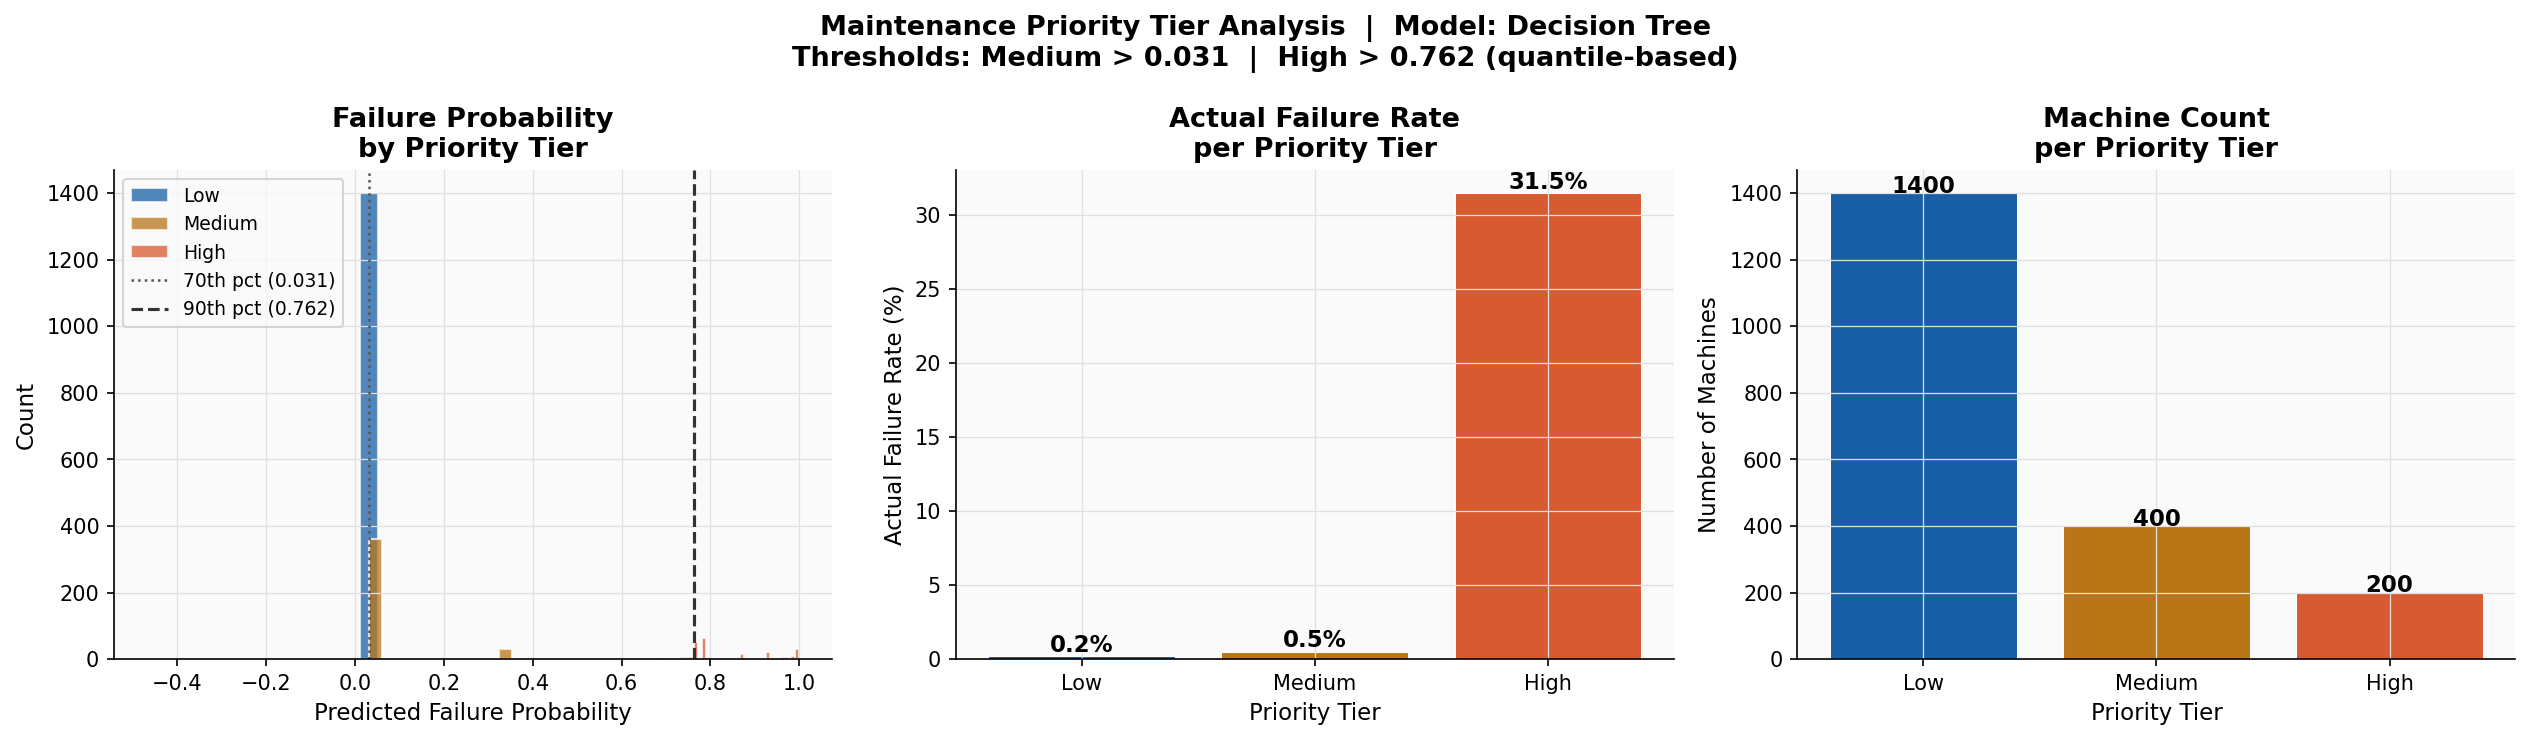

Saved: pred_05_priority_tiers.png


In [29]:
# ============================================================
# E2. Priority tier visualisation — three panels
# ============================================================
tier_colors = {"Low": C_NAVY, "Medium": C_AMBER, "High": C_CORAL}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# A — probability distribution by tier
for tier, grp in priority_df.groupby("Priority_Tier", observed=True):
    axes[0].hist(grp["Failure_Probability"], bins=25,
                 alpha=0.75, label=tier,
                 color=tier_colors[tier], edgecolor="white")
axes[0].axvline(p70, color="#555", lw=1.2, ls=":", label=f"70th pct ({p70:.3f})")
axes[0].axvline(p90, color="#333", lw=1.5, ls="--", label=f"90th pct ({p90:.3f})")
axes[0].set_title("Failure Probability\nby Priority Tier")
axes[0].set_xlabel("Predicted Failure Probability")
axes[0].set_ylabel("Count")
axes[0].legend(fontsize=9)

# B — actual failure rate per tier
tier_fail_rate = (
    priority_df.groupby("Priority_Tier", observed=True)["Actual_Failure"]
    .mean() * 100
)
bars = axes[1].bar(
    tier_fail_rate.index, tier_fail_rate.values,
    color=[tier_colors[t] for t in tier_fail_rate.index],
    edgecolor="white", linewidth=0.5,
)
axes[1].set_title("Actual Failure Rate\nper Priority Tier")
axes[1].set_xlabel("Priority Tier")
axes[1].set_ylabel("Actual Failure Rate (%)")
for bar, val in zip(bars, tier_fail_rate.values):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                 bar.get_height()+0.3,
                 f"{val:.1f}%", ha="center", fontweight="bold", fontsize=11)

# C — machine count per tier
tier_counts = priority_df["Priority_Tier"].value_counts().sort_index()
axes[2].bar(tier_counts.index, tier_counts.values,
            color=[tier_colors[t] for t in tier_counts.index],
            edgecolor="white", linewidth=0.5)
axes[2].set_title("Machine Count\nper Priority Tier")
axes[2].set_xlabel("Priority Tier")
axes[2].set_ylabel("Number of Machines")
for i, (idx, val) in enumerate(tier_counts.items()):
    axes[2].text(i, val+1, str(val), ha="center", fontweight="bold", fontsize=11)

fig.suptitle(
    f"Maintenance Priority Tier Analysis  |  Model: {BEST_MODEL_NAME}\n"
    f"Thresholds: Medium > {p70:.3f}  |  High > {p90:.3f} (quantile-based)",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.savefig(fig_folder / "pred_05_priority_tiers.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: pred_05_priority_tiers.png")


---
## Section F — Output Inventory

In [30]:
# ============================================================
# F1. Print all output files with sizes
# ============================================================
print("All Part 2 output files:")
print("=" * 65)
for f in sorted(output_folder.rglob("*")):
    if f.is_file():
        size_kb = f.stat().st_size / 1024
        print(f"  {str(f.relative_to(output_folder)):<52}  {size_kb:>6.1f} KB")
print("=" * 65)
print("\nPart 2 complete.")


All Part 2 output files:
  cleaned_predictive_maintenance_dataset.csv             594.4 KB
  correlation_with_failure.csv                             0.3 KB
  cv_performance_summary.csv                               0.4 KB
  failure_distribution.csv                                 0.1 KB
  failure_rate_by_type.csv                                 0.1 KB
  failure_rate_by_wear_band.csv                            0.1 KB
  failure_type_breakdown.csv                               0.4 KB
  feature_importance_rf.csv                                0.3 KB
  figures/desc_01_failure_distribution.png               182.1 KB
  figures/desc_02_tool_wear_by_failure.png               265.7 KB
  figures/desc_03_torque_by_failure.png                  273.4 KB
  figures/desc_04_failure_by_type.png                    163.3 KB
  figures/desc_05_correlation_failure.png                237.5 KB
  figures/pred_01_confusion_matrices.png                 171.9 KB
  figures/pred_02_roc_pr_curves.png                

---
## Section G — Interpretation & Recommendations

### Descriptive Analytics — Key Findings

**Dataset profile:**  
The AI4I 2020 dataset contains 10,000 records and 14 variables. After cleaning, 7 sensor  
features (5 raw + 2 engineered) are used alongside product type for prediction.  
The dataset is severely imbalanced — only ~3.4% of machines fail — making Recall and PR-AUC  
the appropriate evaluation metrics rather than accuracy.

**Failure drivers (from descriptive analysis):**  
Tool wear and torque show the strongest associations with failure (highest point-biserial  
correlation and mutual information). Machines that fail have significantly higher median tool  
wear, confirming that cumulative degradation is the dominant risk factor. Torque shows a  
bimodal failure pattern — failures occur at both very high torque (mechanical overstrain)  
and very low torque with high RPM (heat dissipation failure).

**Product type effect:**  
Low-quality (L) products have the highest failure rate. High-quality (H) components are  
more reliable but still fail — product grade alone is insufficient for maintenance targeting.

**Tool wear band — ordinal relationship confirmed:**  
The descriptive failure rate by tool_wear_band table confirms Low < Medium < High in  
failure rate, validating the ordinal encoding choice over one-hot encoding.

### Predictive Analytics — Key Findings

| Item | Detail |
|---|---|
| Best model | Selected by CV Recall then CV PR-AUC — not test scores |
| Primary metric | PR-AUC (correct for imbalanced data) |
| Tuning method | GridSearchCV on all three models, scored on Recall |
| CV approach | 5-fold StratifiedKFold — mean ± std reported |
| Encoding | type → one-hot; tool_wear_band → ordinal (0/1/2) |

### Limitations

1. AI4I is a synthetic benchmark dataset — real deployment requires mine-specific sensor  
   logs, failure records, and operational scheduling constraints.
2. Feature importances reflect correlation, not causality — domain validation is required  
   before acting on them operationally.
3. The model should be monitored for concept drift as sensor distributions shift with  
   equipment age or seasonal underground conditions.

### Recommended Next Steps

- Add SHAP values for individual machine-level explainability
- Acquire mine-specific historical data for domain-adapted retraining
- Connect the priority output to Part 3 prescriptive scheduling optimisation
- Deploy as a weekly batch scoring pipeline triggered by new sensor uploads


## Section H — Prescriptive Analytics

In [31]:
# ============================================================
# H1. Load Maintenance Priority Output from Predictive Analytics
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


project_root = Path.cwd()
output_folder = project_root / "output"
fig_folder = output_folder / "figures"

output_folder.mkdir(parents=True, exist_ok=True)
fig_folder.mkdir(parents=True, exist_ok=True)


priority_path = output_folder / "maintenance_priority_output.csv"

priority_df = pd.read_csv(priority_path)

print("Maintenance priority output loaded successfully.")
print("Dataset shape:", priority_df.shape)
print("\nColumns available:")
print(priority_df.columns.tolist())

display(priority_df.head())

Maintenance priority output loaded successfully.
Dataset shape: (2000, 14)

Columns available:
['air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'temp_difference_k', 'tool_wear_band', 'type_L', 'type_M', 'Actual_Failure', 'Failure_Probability', 'Predicted_Class', 'Risk_Percentile', 'Priority_Tier']


,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,temp_difference_k,tool_wear_band,type_L,type_M,Actual_Failure,Failure_Probability,Predicted_Class,Risk_Percentile,Priority_Tier
0,303.4,311.8,1341,47.0,210,8.4,2,0,1,1,1.0,1,1.0000,High
1,303.7,312.1,1363,51.8,90,8.4,1,1,0,1,1.0,1,0.9910,High
2,301.7,309.8,1284,68.2,111,8.1,1,0,1,1,1.0,1,0.9995,High
3,303.3,311.3,1350,48.1,32,8.0,0,1,0,1,1.0,1,0.9990,High
4,302.7,311.1,1297,60.7,125,8.4,1,0,1,1,1.0,1,0.9985,High


In [32]:
# ============================================================
# H2. Check Required Columns for Prescriptive Analytics
# ============================================================

required_cols = ["Failure_Probability", "Actual_Failure", "Predicted_Class", "Priority_Tier"]

missing_cols = [col for col in required_cols if col not in priority_df.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")
else:
    print("All required columns are available for prescriptive analytics.")

print("\nFailure probability summary:")
display(priority_df["Failure_Probability"].describe().to_frame())

print("\nPriority tier distribution:")
display(priority_df["Priority_Tier"].value_counts().to_frame("count"))

All required columns are available for prescriptive analytics.

Failure probability summary:


,Failure_Probability
count,2000.000000
mean,0.120964
std,0.252222
min,0.030800
25%,0.030800
50%,0.030800
75%,0.030800
max,1.000000



Priority tier distribution:


,count
Priority_Tier,
Low,1400
Medium,400
High,200


### H3 — Prescriptive Optimisation Logic

The predictive model estimates the probability that each machine will fail. The prescriptive analytics stage converts those predicted probabilities into a maintenance allocation decision.

The decision variable is binary:

xᵢ = 1 if machine i is selected for maintenance  
xᵢ = 0 if machine i is not selected for maintenance

The objective is to maximise the total expected avoided failure loss:

Maximise Σ(pᵢ × C × xᵢ)

where pᵢ is the predicted failure probability for machine i, C is the assumed downtime cost per failure, and xᵢ is the maintenance selection decision.

The main constraint is the available maintenance-hour budget:

Σ(hᵢ × xᵢ) ≤ H

where hᵢ is the maintenance time required for machine i and H is the total available maintenance hours.

Base-case assumptions:
- Downtime cost per failure = $10,000
- Maintenance time per machine = 2 hours
- Available weekly maintenance hours = 40 hours

These are scenario assumptions because the public AI4I dataset does not include actual downtime costs, labour rosters, or repair-duration records.

In [33]:
import pulp
import inspect

print("PuLP version:", getattr(pulp, "__version__", "unknown"))
print("PuLP location:", pulp.__file__)
print("LpVariable signature:", inspect.signature(pulp.LpVariable))

PuLP version: 2.9.0
PuLP location: /usr/local/lib/python3.13/dist-packages/pulp/__init__.py
LpVariable signature: (name, lowBound=None, upBound=None, cat='Continuous', e=None)


In [34]:
%pip install --force-reinstall "pulp==2.9.0"

  Using cached PuLP-2.9.0-py3-none-any.whl.metadata (5.4 kB)
Using cached PuLP-2.9.0-py3-none-any.whl (17.7 MB)
  Attempting uninstall: pulp
    Found existing installation: PuLP 2.9.0
    Uninstalling PuLP-2.9.0:
      Successfully uninstalled PuLP-2.9.0


In [35]:
import pulp
print(pulp.__version__)

2.9.0


In [36]:
# ============================================================
# H4. Base-Case Integer Linear Programming Model using PuLP
# ============================================================

# Install PuLP
try:
    import pulp
    print("PuLP is already installed.")
except ImportError:
    !pip install pulp -q
    import pulp
    print("PuLP installed successfully.")

# -----------------------------
# Base-case assumptions
# -----------------------------
DOWNTIME_COST = 10000          # assumed cost per failure
MAINTENANCE_TIME = 2           # hours required per selected machine
AVAILABLE_HOURS = 40           # weekly maintenance-hour capacity

# Copy priority data for optimisation
opt_df = priority_df.copy().reset_index(drop=True)

# Create expected avoided loss score
opt_df["Expected_Avoided_Loss"] = (
    opt_df["Failure_Probability"] * DOWNTIME_COST
)

# Create machine ID for optimisation
opt_df["Machine_ID"] = opt_df.index

# -----------------------------
# Define ILP model
# -----------------------------
model = pulp.LpProblem(
    "Maintenance_Time_Allocation_Optimisation",
    pulp.LpMaximize
)

# Binary decision variable:
# x_i = 1 if machine i is selected for maintenance, 0 otherwise
x = {
    i: pulp.LpVariable(f"x_{i}", cat="Binary")
    for i in opt_df["Machine_ID"]
}

# Objective function:
# Maximise total expected avoided failure loss
model += pulp.lpSum(
    opt_df.loc[i, "Expected_Avoided_Loss"] * x[i]
    for i in opt_df["Machine_ID"]
), "Total_Expected_Avoided_Loss"

# Constraint:
# Total maintenance hours must not exceed available weekly capacity
model += pulp.lpSum(
    MAINTENANCE_TIME * x[i]
    for i in opt_df["Machine_ID"]
) <= AVAILABLE_HOURS, "Maintenance_Hour_Budget"

# -----------------------------
# Solve model
# -----------------------------
model.solve(pulp.PULP_CBC_CMD(msg=False))

print("Solver status:", pulp.LpStatus[model.status])
print("Objective value:", round(pulp.value(model.objective), 2))

PuLP is already installed.
Solver status: Optimal
Objective value: 199937.0


In [37]:
# ============================================================
# H5. Base-Case Optimisation Results
# ============================================================

# Store optimisation decision
opt_df["Selected_for_Maintenance"] = opt_df["Machine_ID"].apply(
    lambda i: int(pulp.value(x[i]))
)

# Store maintenance hours used
opt_df["Maintenance_Hours"] = (
    opt_df["Selected_for_Maintenance"] * MAINTENANCE_TIME
)

# Selected maintenance schedule
selected_schedule = opt_df[opt_df["Selected_for_Maintenance"] == 1].copy()

selected_schedule = selected_schedule.sort_values(
    "Failure_Probability",
    ascending=False
).reset_index(drop=True)

# Base-case summary
base_case_summary = pd.DataFrame({
    "Metric": [
        "Available maintenance hours",
        "Maintenance time per machine",
        "Downtime cost assumption",
        "Machines selected",
        "Total maintenance hours used",
        "Average selected failure probability",
        "Maximum selected failure probability",
        "Minimum selected failure probability",
        "Total expected avoided failure loss"
    ],
    "Value": [
        AVAILABLE_HOURS,
        MAINTENANCE_TIME,
        DOWNTIME_COST,
        int(selected_schedule["Selected_for_Maintenance"].sum()),
        selected_schedule["Maintenance_Hours"].sum(),
        round(selected_schedule["Failure_Probability"].mean(), 4),
        round(selected_schedule["Failure_Probability"].max(), 4),
        round(selected_schedule["Failure_Probability"].min(), 4),
        round(selected_schedule["Expected_Avoided_Loss"].sum(), 2)
    ]
})

print("Base-case optimisation summary:")
display(base_case_summary)

print("\nSelected machines for maintenance:")
display(
    selected_schedule[
        [
            "Machine_ID",
            "Failure_Probability",
            "Expected_Avoided_Loss",
            "Priority_Tier",
            "Predicted_Class",
            "Actual_Failure",
            "Maintenance_Hours"
        ]
    ].head(25)
)

Base-case optimisation summary:


,Metric,Value
0,Available maintenance hours,40.0000
1,Maintenance time per machine,2.0000
2,Downtime cost assumption,10000.0000
3,Machines selected,20.0000
4,Total maintenance hours used,40.0000
5,Average selected failure probability,0.9997
6,Maximum selected failure probability,1.0000
7,Minimum selected failure probability,0.9937
8,Total expected avoided failure loss,199937.0000



Selected machines for maintenance:


,Machine_ID,Failure_Probability,Expected_Avoided_Loss,Priority_Tier,Predicted_Class,Actual_Failure,Maintenance_Hours
0,0,1.0000,10000.0,High,1,1,2
1,1,1.0000,10000.0,High,1,1,2
2,2,1.0000,10000.0,High,1,1,2
3,3,1.0000,10000.0,High,1,1,2
4,4,1.0000,10000.0,High,1,1,2
5,5,1.0000,10000.0,High,1,1,2
6,6,1.0000,10000.0,High,1,1,2
7,7,1.0000,10000.0,High,1,1,2
8,8,1.0000,10000.0,High,1,1,2
9,9,1.0000,10000.0,High,1,1,2


In [38]:
# ============================================================
# H6. Save Base-Case Prescriptive Outputs
# ============================================================

base_case_summary.to_csv(
    output_folder / "prescriptive_base_case_summary.csv",
    index=False
)

selected_schedule.to_csv(
    output_folder / "prescriptive_base_case_selected_machines.csv",
    index=False
)

opt_df.to_csv(
    output_folder / "prescriptive_all_machine_decisions.csv",
    index=False
)

print("Base-case prescriptive outputs saved successfully.")
print("Saved files:")
print("- prescriptive_base_case_summary.csv")
print("- prescriptive_base_case_selected_machines.csv")
print("- prescriptive_all_machine_decisions.csv")

Base-case prescriptive outputs saved successfully.
Saved files:
- prescriptive_base_case_summary.csv
- prescriptive_base_case_selected_machines.csv
- prescriptive_all_machine_decisions.csv


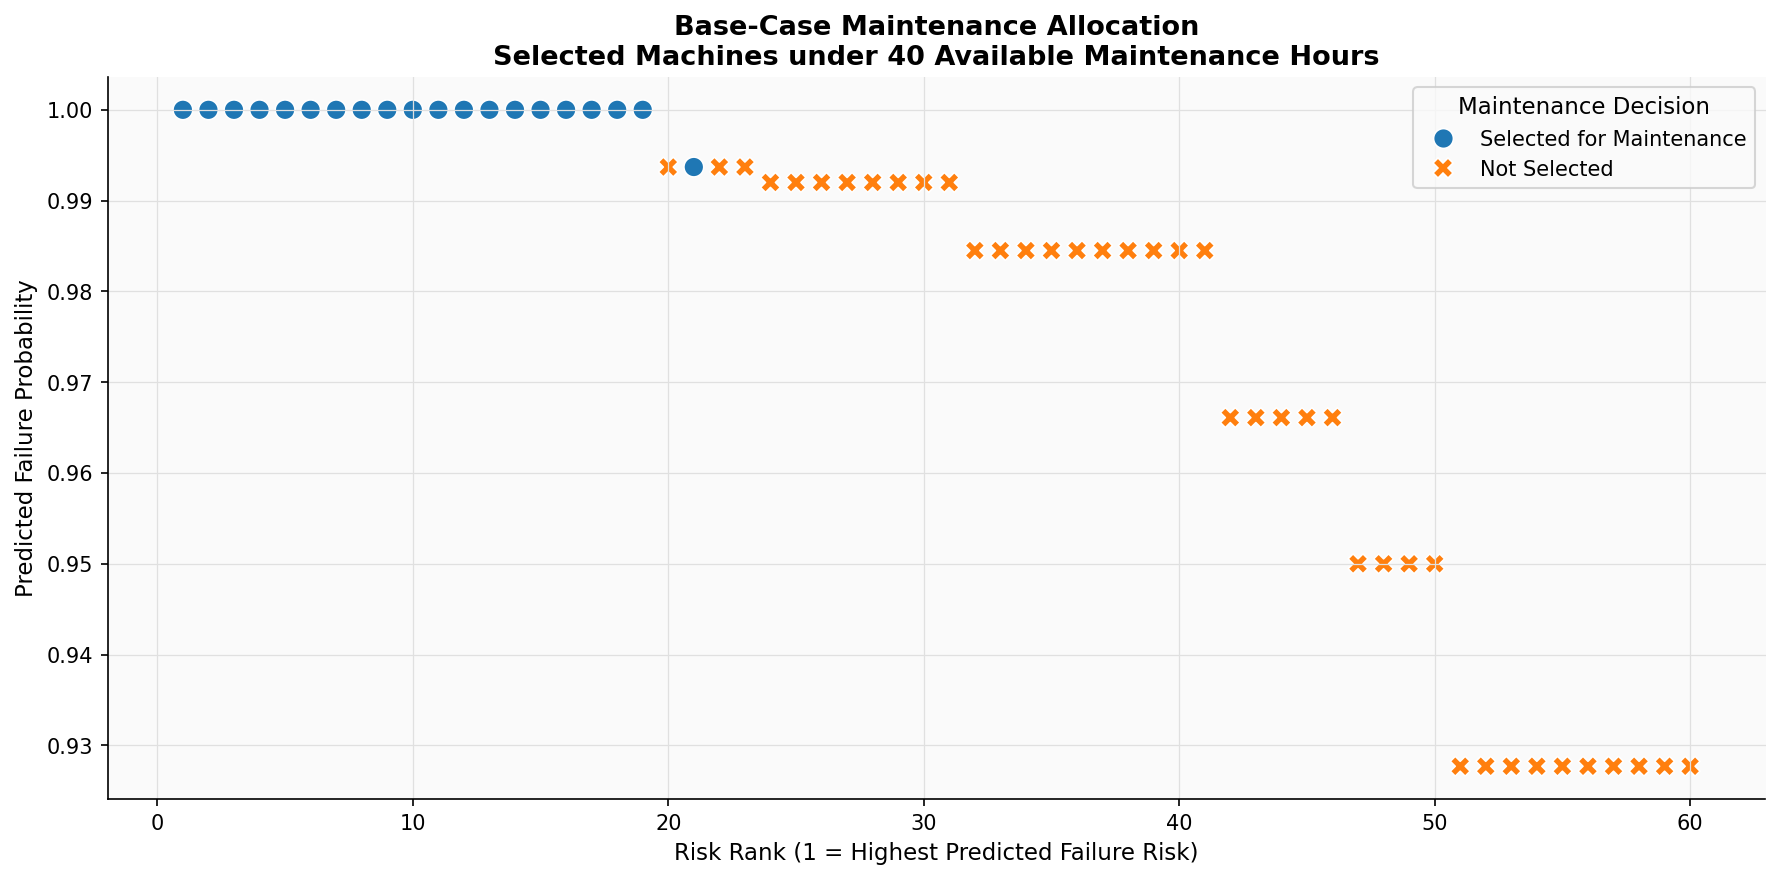

Saved: prescriptive_01_base_case_allocation.png


In [39]:
# ============================================================
# H7. Visualise Base-Case Maintenance Allocation
# ============================================================

# Create a plotting copy
plot_df = opt_df.copy()

# Sort by failure probability for clearer visualisation
plot_df = plot_df.sort_values("Failure_Probability", ascending=False).reset_index(drop=True)

# Add rank after sorting
plot_df["Risk_Rank"] = plot_df.index + 1

# Focus on top 60 machines for readability
top_plot_df = plot_df.head(60).copy()

plt.figure(figsize=(12, 6))

colors = top_plot_df["Selected_for_Maintenance"].map({
    1: "Selected for Maintenance",
    0: "Not Selected"
})

sns.scatterplot(
    data=top_plot_df,
    x="Risk_Rank",
    y="Failure_Probability",
    hue=colors,
    style=colors,
    s=90
)

plt.title(
    "Base-Case Maintenance Allocation\n"
    "Selected Machines under 40 Available Maintenance Hours"
)
plt.xlabel("Risk Rank (1 = Highest Predicted Failure Risk)")
plt.ylabel("Predicted Failure Probability")
plt.legend(title="Maintenance Decision")
plt.tight_layout()

plt.savefig(
    fig_folder / "prescriptive_01_base_case_allocation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: prescriptive_01_base_case_allocation.png")

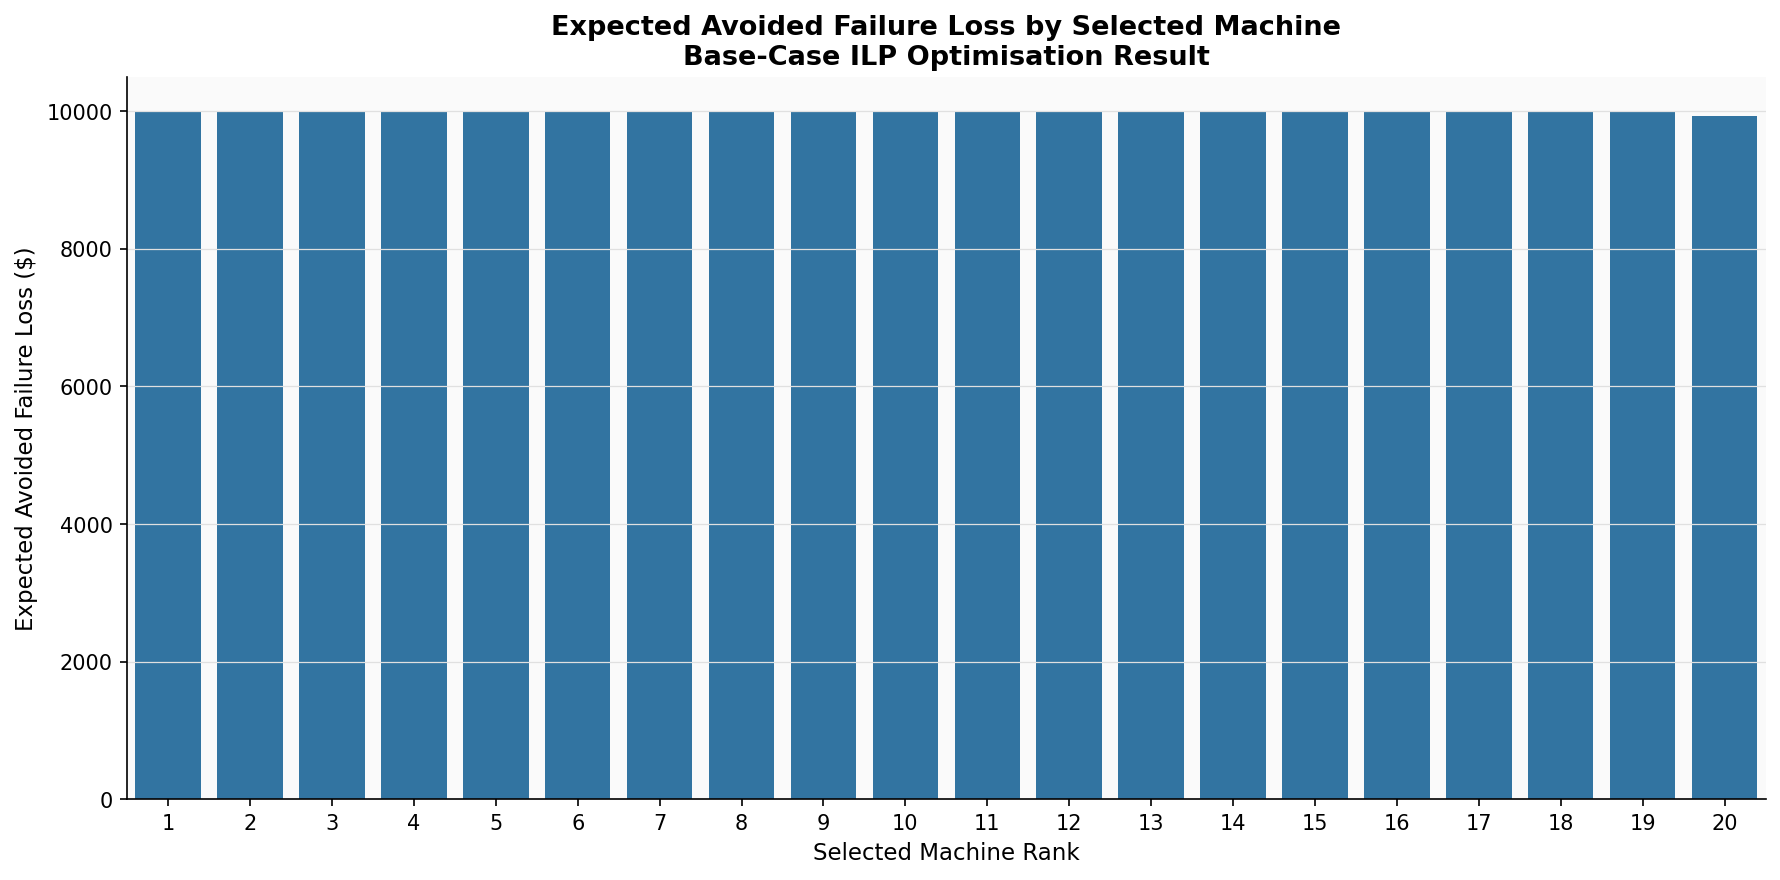

Saved: prescriptive_02_selected_machine_expected_loss.png


In [40]:
# ============================================================
# H8. Visualise Expected Avoided Loss for Selected Machines
# ============================================================

selected_plot_df = selected_schedule.copy()
selected_plot_df["Selection_Rank"] = selected_plot_df.index + 1

plt.figure(figsize=(12, 6))

sns.barplot(
    data=selected_plot_df,
    x="Selection_Rank",
    y="Expected_Avoided_Loss"
)

plt.title(
    "Expected Avoided Failure Loss by Selected Machine\n"
    "Base-Case ILP Optimisation Result"
)
plt.xlabel("Selected Machine Rank")
plt.ylabel("Expected Avoided Failure Loss ($)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    fig_folder / "prescriptive_02_selected_machine_expected_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: prescriptive_02_selected_machine_expected_loss.png")

### Base-Case Prescriptive Interpretation

The ILP model selected the machines with the highest expected avoided failure loss while staying within the 40-hour weekly maintenance constraint. Because each selected machine is assumed to require 2 hours of maintenance, the base-case capacity allows 20 machines to be selected.

The result translates predictive analytics into a feasible maintenance action plan. Instead of only ranking machines by failure probability, the optimisation model formally decides which machines should receive maintenance under a limited maintenance-hour budget.

## Section I — What-if Scenarios and Sensitivity Analysis

The base-case optimisation provides one recommended maintenance allocation under the assumed conditions of 40 available maintenance hours, 2 hours per machine, and $10,000 downtime cost per failure.

However, maintenance decisions may change when operating conditions or resource constraints change. This section tests how robust the recommendation is under different scenarios by varying:

1. Available maintenance hours  
2. Downtime cost per failure  
3. Maintenance time per machine  
4. Classification/risk threshold  

These what-if scenarios help the maintenance manager understand whether the recommended maintenance allocation remains useful under changing business conditions.

In [41]:
# ============================================================
# I1. Reusable ILP Optimisation Function
# ============================================================

def run_maintenance_ilp(
    data,
    available_hours=40,
    maintenance_time_per_machine=2,
    downtime_cost=10000,
    min_probability_threshold=None
):
    """
    Runs binary ILP maintenance allocation.

    Objective:
    Maximise total expected avoided failure loss.

    Constraint:
    Total maintenance hours must not exceed available hours.

    Optional:
    Only machines above a minimum failure probability threshold can be selected.
    """

    scenario_df = data.copy().reset_index(drop=True)

    scenario_df["Machine_ID"] = scenario_df.index
    scenario_df["Expected_Avoided_Loss"] = (
        scenario_df["Failure_Probability"] * downtime_cost
    )

    # If threshold is applied, only eligible machines can be selected
    if min_probability_threshold is not None:
        scenario_df["Eligible"] = (
            scenario_df["Failure_Probability"] >= min_probability_threshold
        ).astype(int)
    else:
        scenario_df["Eligible"] = 1

    # Define ILP model
    scenario_model = pulp.LpProblem(
        "Maintenance_Allocation_Scenario",
        pulp.LpMaximize
    )

    # Binary decision variables
    x_scenario = {
        i: pulp.LpVariable(f"x_{i}", cat="Binary")
        for i in scenario_df["Machine_ID"]
    }

    # Objective function
    scenario_model += pulp.lpSum(
        scenario_df.loc[i, "Expected_Avoided_Loss"] * x_scenario[i]
        for i in scenario_df["Machine_ID"]
    ), "Total_Expected_Avoided_Loss"

    # Maintenance-hour constraint
    scenario_model += pulp.lpSum(
        maintenance_time_per_machine * x_scenario[i]
        for i in scenario_df["Machine_ID"]
    ) <= available_hours, "Maintenance_Hour_Budget"

    # Eligibility constraint if threshold is applied
    for i in scenario_df["Machine_ID"]:
        scenario_model += x_scenario[i] <= scenario_df.loc[i, "Eligible"]

    # Solve
    scenario_model.solve(pulp.PULP_CBC_CMD(msg=False))

    # Store decision
    scenario_df["Selected_for_Maintenance"] = scenario_df["Machine_ID"].apply(
        lambda i: int(pulp.value(x_scenario[i]))
    )

    scenario_df["Maintenance_Hours"] = (
        scenario_df["Selected_for_Maintenance"] * maintenance_time_per_machine
    )

    selected = scenario_df[scenario_df["Selected_for_Maintenance"] == 1].copy()

    # Summary output
    summary = {
        "Available maintenance hours": available_hours,
        "Maintenance time per machine": maintenance_time_per_machine,
        "Downtime cost assumption": downtime_cost,
        "Minimum probability threshold": min_probability_threshold,
        "Machines selected": int(selected["Selected_for_Maintenance"].sum()) if len(selected) > 0 else 0,
        "Total hours used": round(selected["Maintenance_Hours"].sum(), 2) if len(selected) > 0 else 0,
        "Average selected failure probability": round(selected["Failure_Probability"].mean(), 4) if len(selected) > 0 else 0,
        "Minimum selected failure probability": round(selected["Failure_Probability"].min(), 4) if len(selected) > 0 else 0,
        "Maximum selected failure probability": round(selected["Failure_Probability"].max(), 4) if len(selected) > 0 else 0,
        "Total expected avoided failure loss": round(selected["Expected_Avoided_Loss"].sum(), 2) if len(selected) > 0 else 0,
        "Solver status": pulp.LpStatus[scenario_model.status]
    }

    return scenario_df, selected, summary

In [42]:
# ============================================================
# I2. What-if Scenario 1 — Maintenance-Hour Sensitivity
# ============================================================

maintenance_hour_scenarios = [20, 40, 60, 80]

hour_sensitivity_results = []

for hours in maintenance_hour_scenarios:
    scenario_df, selected, summary = run_maintenance_ilp(
        data=priority_df,
        available_hours=hours,
        maintenance_time_per_machine=2,
        downtime_cost=10000
    )

    summary["Scenario"] = f"{hours} maintenance hours"
    hour_sensitivity_results.append(summary)

hour_sensitivity_df = pd.DataFrame(hour_sensitivity_results)

# Reorder columns
hour_sensitivity_df = hour_sensitivity_df[
    [
        "Scenario",
        "Available maintenance hours",
        "Maintenance time per machine",
        "Machines selected",
        "Total hours used",
        "Average selected failure probability",
        "Total expected avoided failure loss",
        "Solver status"
    ]
]

display(hour_sensitivity_df)

hour_sensitivity_df.to_csv(
    output_folder / "whatif_maintenance_hour_sensitivity.csv",
    index=False
)

print("Saved: whatif_maintenance_hour_sensitivity.csv")

,Scenario,Available maintenance hours,Maintenance time per machine,Machines selected,Total hours used,Average selected failure probability,Total expected avoided failure loss,Solver status
0,20 maintenance hours,20,2,10,20,1.0000,100000.0,Optimal
1,40 maintenance hours,40,2,20,40,0.9997,199937.0,Optimal
2,60 maintenance hours,60,2,30,60,0.9973,299188.0,Optimal
3,80 maintenance hours,80,2,40,80,0.9943,397713.0,Optimal


Saved: whatif_maintenance_hour_sensitivity.csv


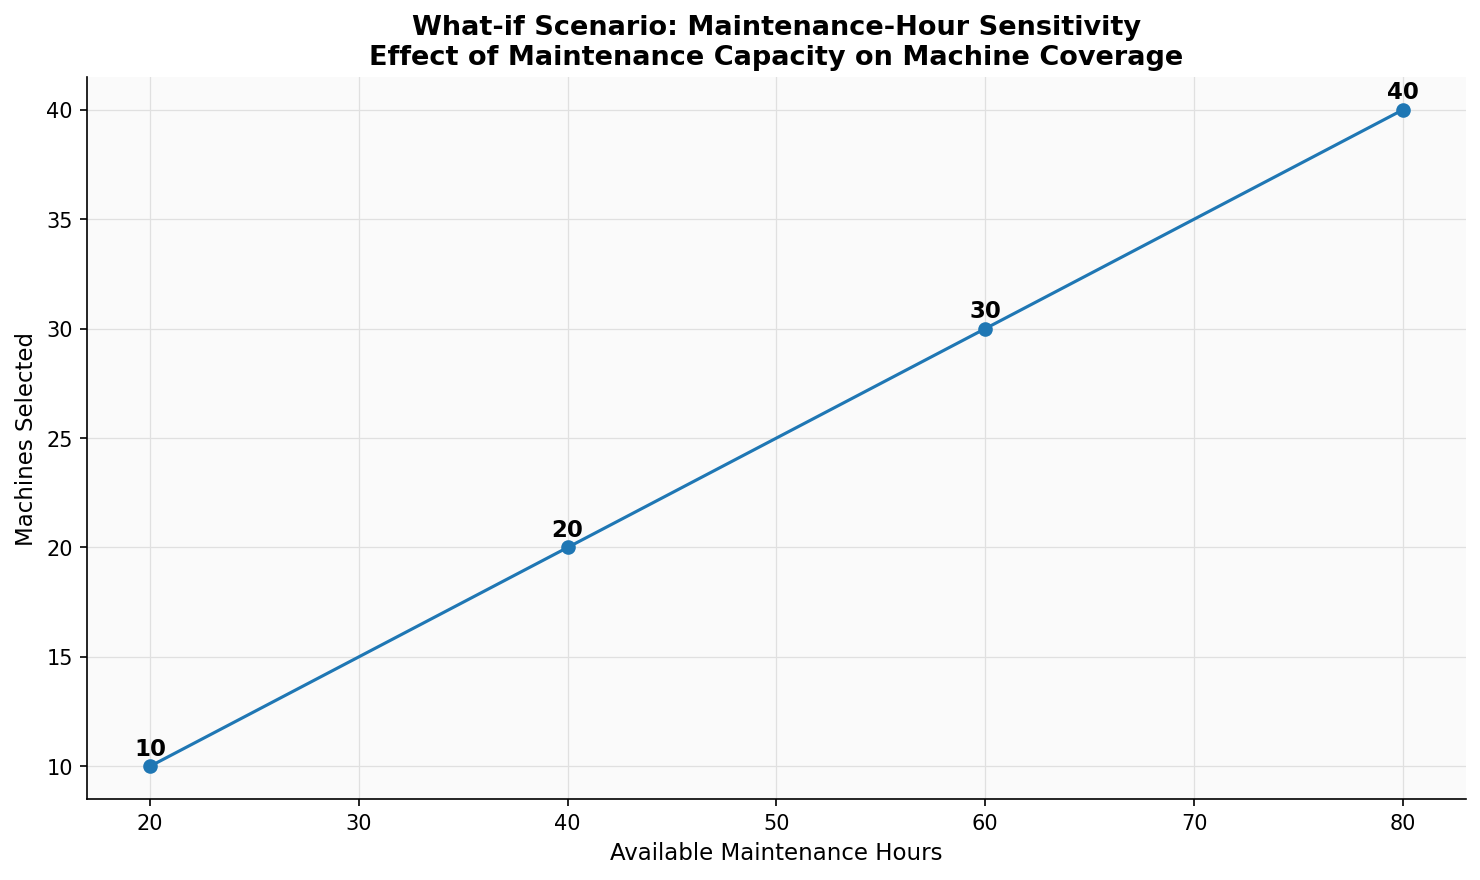

Saved: whatif_01_maintenance_hour_sensitivity.png


In [43]:
# ============================================================
# I3. Visualise Maintenance-Hour Sensitivity
# ============================================================

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    hour_sensitivity_df["Available maintenance hours"],
    hour_sensitivity_df["Machines selected"],
    marker="o",
    label="Machines selected"
)

ax1.set_xlabel("Available Maintenance Hours")
ax1.set_ylabel("Machines Selected")
ax1.set_title(
    "What-if Scenario: Maintenance-Hour Sensitivity\n"
    "Effect of Maintenance Capacity on Machine Coverage"
)

for x_val, y_val in zip(
    hour_sensitivity_df["Available maintenance hours"],
    hour_sensitivity_df["Machines selected"]
):
    ax1.text(x_val, y_val + 0.5, str(y_val), ha="center", fontweight="bold")

plt.tight_layout()

plt.savefig(
    fig_folder / "whatif_01_maintenance_hour_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: whatif_01_maintenance_hour_sensitivity.png")

### Maintenance-Hour Sensitivity Interpretation

This scenario tests how the recommended maintenance allocation changes when available maintenance capacity changes. As the number of available maintenance hours increases, the ILP model can select more machines for maintenance. Under limited capacity, only the highest-risk machines are selected. Under expanded capacity, the model can include additional machines with lower but still relevant failure risk.

This scenario is important because maintenance teams often face labour constraints. The result shows how the recommended action changes when fewer or more maintenance hours are available.

In [44]:
# ============================================================
# I4. What-if Scenario 2 — Downtime-Cost Sensitivity
# ============================================================

downtime_cost_scenarios = [5000, 10000, 20000]

cost_sensitivity_results = []

for cost in downtime_cost_scenarios:
    scenario_df, selected, summary = run_maintenance_ilp(
        data=priority_df,
        available_hours=40,
        maintenance_time_per_machine=2,
        downtime_cost=cost
    )

    summary["Scenario"] = f"${cost:,} downtime cost"
    cost_sensitivity_results.append(summary)

cost_sensitivity_df = pd.DataFrame(cost_sensitivity_results)

# Reorder columns
cost_sensitivity_df = cost_sensitivity_df[
    [
        "Scenario",
        "Available maintenance hours",
        "Maintenance time per machine",
        "Downtime cost assumption",
        "Machines selected",
        "Total hours used",
        "Average selected failure probability",
        "Total expected avoided failure loss",
        "Solver status"
    ]
]

display(cost_sensitivity_df)

cost_sensitivity_df.to_csv(
    output_folder / "whatif_downtime_cost_sensitivity.csv",
    index=False
)

print("Saved: whatif_downtime_cost_sensitivity.csv")

,Scenario,Available maintenance hours,Maintenance time per machine,Downtime cost assumption,Machines selected,Total hours used,Average selected failure probability,Total expected avoided failure loss,Solver status
0,"$5,000 downtime cost",40,2,5000,20,40,0.9997,99968.5,Optimal
1,"$10,000 downtime cost",40,2,10000,20,40,0.9997,199937.0,Optimal
2,"$20,000 downtime cost",40,2,20000,20,40,0.9997,399874.0,Optimal


Saved: whatif_downtime_cost_sensitivity.csv


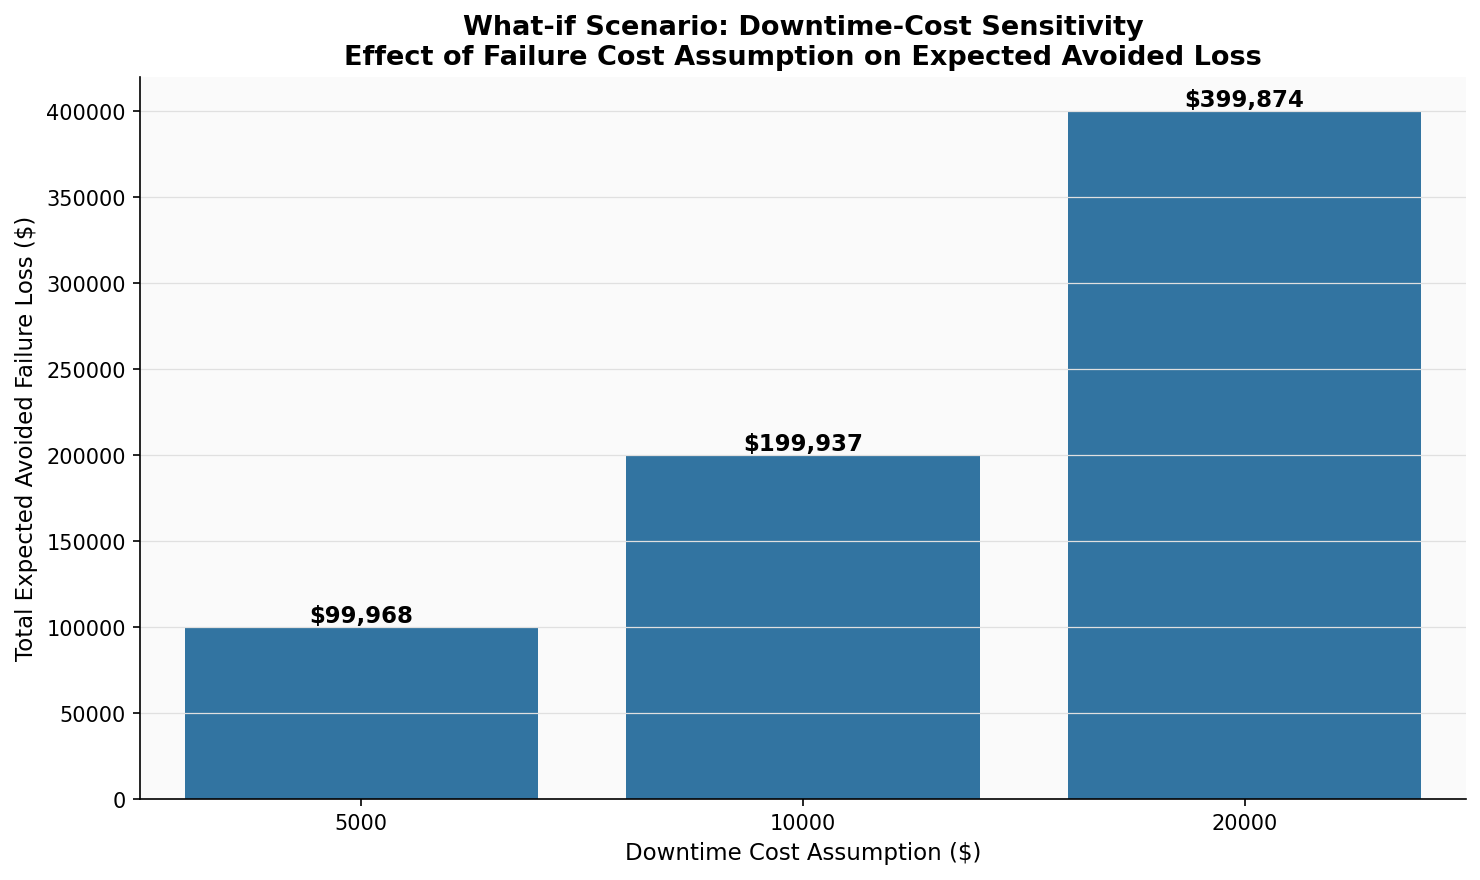

Saved: whatif_02_downtime_cost_sensitivity.png


In [45]:
# ============================================================
# I5. Visualise Downtime-Cost Sensitivity
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=cost_sensitivity_df,
    x="Downtime cost assumption",
    y="Total expected avoided failure loss"
)

plt.title(
    "What-if Scenario: Downtime-Cost Sensitivity\n"
    "Effect of Failure Cost Assumption on Expected Avoided Loss"
)
plt.xlabel("Downtime Cost Assumption ($)")
plt.ylabel("Total Expected Avoided Failure Loss ($)")

# Add value labels
for index, row in cost_sensitivity_df.iterrows():
    plt.text(
        index,
        row["Total expected avoided failure loss"],
        f"${row['Total expected avoided failure loss']:,.0f}",
        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    fig_folder / "whatif_02_downtime_cost_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: whatif_02_downtime_cost_sensitivity.png")

### Downtime-Cost Sensitivity Interpretation

This scenario tests how the expected business value of the maintenance allocation changes when the assumed cost of machine failure changes. The selected machines may remain similar because the ranking is still mainly driven by predicted failure probability. However, the total expected avoided failure loss increases as the assumed downtime cost increases.

This is important because the public dataset does not contain actual mining downtime-cost data. Therefore, the cost assumption should be treated as a scenario value rather than an actual financial saving.

In [46]:
# ============================================================
# I6. What-if Scenario 3 — Maintenance-Duration Sensitivity
# ============================================================

maintenance_duration_scenarios = [1.5, 2.0, 3.0]

duration_sensitivity_results = []

for duration in maintenance_duration_scenarios:
    scenario_df, selected, summary = run_maintenance_ilp(
        data=priority_df,
        available_hours=40,
        maintenance_time_per_machine=duration,
        downtime_cost=10000
    )

    summary["Scenario"] = f"{duration} hours per machine"
    duration_sensitivity_results.append(summary)

duration_sensitivity_df = pd.DataFrame(duration_sensitivity_results)

# Reorder columns
duration_sensitivity_df = duration_sensitivity_df[
    [
        "Scenario",
        "Available maintenance hours",
        "Maintenance time per machine",
        "Machines selected",
        "Total hours used",
        "Average selected failure probability",
        "Total expected avoided failure loss",
        "Solver status"
    ]
]

display(duration_sensitivity_df)

duration_sensitivity_df.to_csv(
    output_folder / "whatif_maintenance_duration_sensitivity.csv",
    index=False
)

print("Saved: whatif_maintenance_duration_sensitivity.csv")

,Scenario,Available maintenance hours,Maintenance time per machine,Machines selected,Total hours used,Average selected failure probability,Total expected avoided failure loss,Solver status
0,1.5 hours per machine,40,1.5,26,39.0,0.9981,259508.0,Optimal
1,2.0 hours per machine,40,2.0,20,40.0,0.9997,199937.0,Optimal
2,3.0 hours per machine,40,3.0,13,39.0,1.0000,130000.0,Optimal


Saved: whatif_maintenance_duration_sensitivity.csv


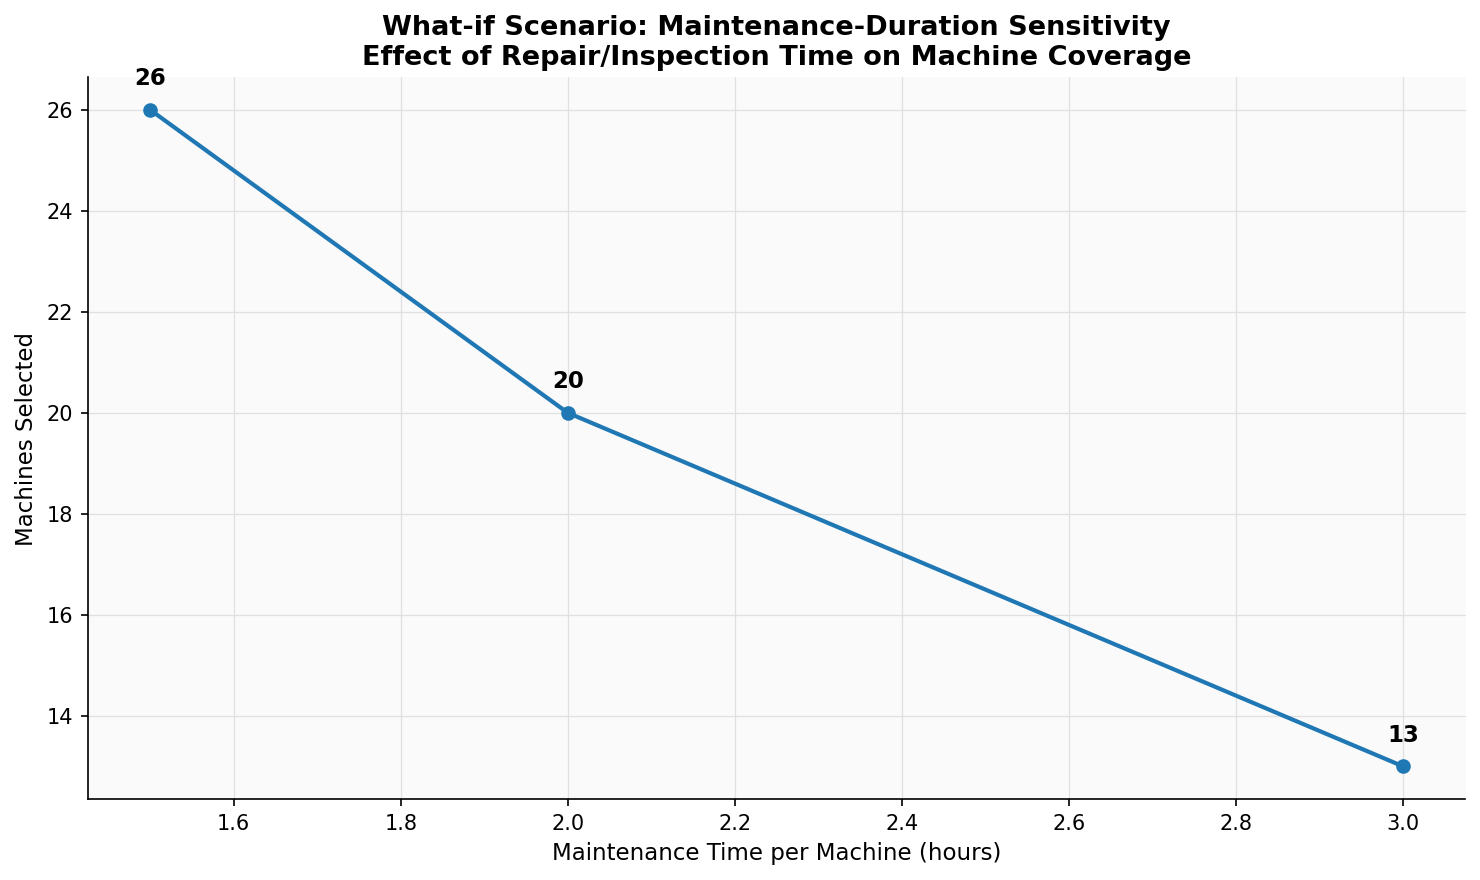

Saved: whatif_03_maintenance_duration_sensitivity.png


In [47]:
# ============================================================
# I7. Visualise Maintenance-Duration Sensitivity
# ============================================================

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    duration_sensitivity_df["Maintenance time per machine"],
    duration_sensitivity_df["Machines selected"],
    marker="o",
    linewidth=2
)

ax1.set_xlabel("Maintenance Time per Machine (hours)")
ax1.set_ylabel("Machines Selected")
ax1.set_title(
    "What-if Scenario: Maintenance-Duration Sensitivity\n"
    "Effect of Repair/Inspection Time on Machine Coverage"
)

for x_val, y_val in zip(
    duration_sensitivity_df["Maintenance time per machine"],
    duration_sensitivity_df["Machines selected"]
):
    ax1.text(
        x_val,
        y_val + 0.5,
        str(y_val),
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    fig_folder / "whatif_03_maintenance_duration_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: whatif_03_maintenance_duration_sensitivity.png")

### Maintenance-Duration Sensitivity Interpretation

This scenario tests how the recommended maintenance allocation changes when each selected machine requires more or less maintenance time. If each machine requires fewer hours, the maintenance team can cover more machines within the same 40-hour weekly capacity. If maintenance duration increases, fewer machines can be selected, making risk-based prioritisation more important.

This scenario is relevant because actual repair or inspection time can vary depending on machine condition, spare-part availability, and maintenance complexity. Since the AI4I dataset does not provide real repair-duration records, the values used here are scenario assumptions.

In [48]:
# ============================================================
# I8. What-if Scenario 4 — Failure-Probability Threshold Sensitivity
# ============================================================

threshold_scenarios = [0.90, 0.95, 0.99, 0.995, 1.00]
threshold_sensitivity_results = []

for threshold in threshold_scenarios:
    scenario_df, selected, summary = run_maintenance_ilp(
        data=priority_df,
        available_hours=40,
        maintenance_time_per_machine=2,
        downtime_cost=10000,
        min_probability_threshold=threshold
    )

    summary["Scenario"] = f"Minimum probability threshold = {threshold}"
    threshold_sensitivity_results.append(summary)

threshold_sensitivity_df = pd.DataFrame(threshold_sensitivity_results)

# Reorder columns
threshold_sensitivity_df = threshold_sensitivity_df[
    [
        "Scenario",
        "Minimum probability threshold",
        "Available maintenance hours",
        "Maintenance time per machine",
        "Machines selected",
        "Total hours used",
        "Average selected failure probability",
        "Minimum selected failure probability",
        "Total expected avoided failure loss",
        "Solver status"
    ]
]

display(threshold_sensitivity_df)

threshold_sensitivity_df.to_csv(
    output_folder / "whatif_probability_threshold_sensitivity.csv",
    index=False
)

print("Saved: whatif_probability_threshold_sensitivity.csv")

,Scenario,Minimum probability threshold,Available maintenance hours,Maintenance time per machine,Machines selected,Total hours used,Average selected failure probability,Minimum selected failure probability,Total expected avoided failure loss,Solver status
0,Minimum probability threshold = 0.9,0.900,40,2,20,40,0.9997,0.9937,199937.0,Optimal
1,Minimum probability threshold = 0.95,0.950,40,2,20,40,0.9997,0.9937,199937.0,Optimal
2,Minimum probability threshold = 0.99,0.990,40,2,20,40,0.9997,0.9937,199937.0,Optimal
3,Minimum probability threshold = 0.995,0.995,40,2,19,38,1.0000,1.0000,190000.0,Optimal
4,Minimum probability threshold = 1.0,1.000,40,2,19,38,1.0000,1.0000,190000.0,Optimal


Saved: whatif_probability_threshold_sensitivity.csv


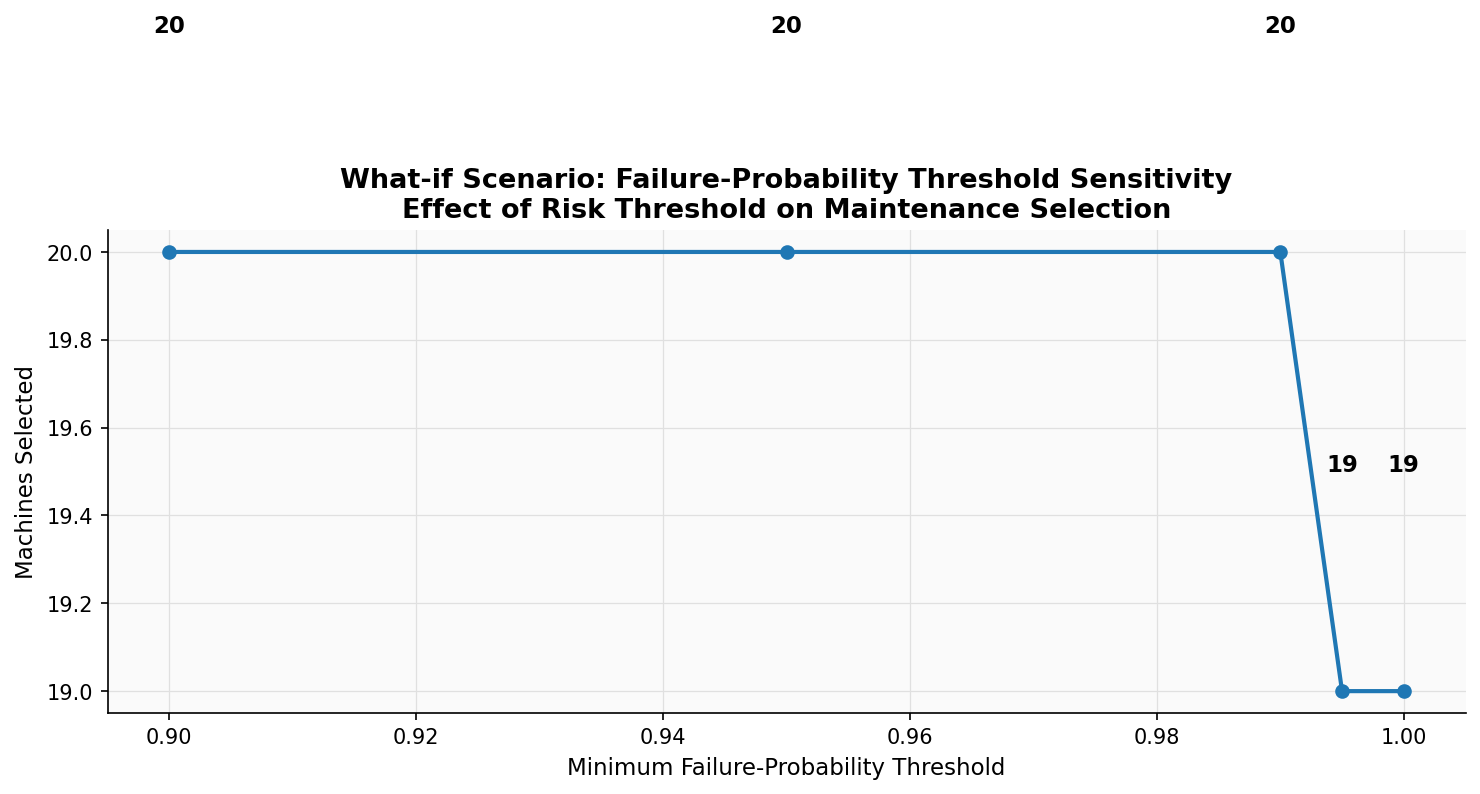

Saved: whatif_04_probability_threshold_sensitivity.png


In [49]:
# ============================================================
# I9. Visualise Failure-Probability Threshold Sensitivity
# ============================================================

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    threshold_sensitivity_df["Minimum probability threshold"],
    threshold_sensitivity_df["Machines selected"],
    marker="o",
    linewidth=2,
    label="Machines selected"
)

ax1.set_xlabel("Minimum Failure-Probability Threshold")
ax1.set_ylabel("Machines Selected")
ax1.set_title(
    "What-if Scenario: Failure-Probability Threshold Sensitivity\n"
    "Effect of Risk Threshold on Maintenance Selection"
)

for x_val, y_val in zip(
    threshold_sensitivity_df["Minimum probability threshold"],
    threshold_sensitivity_df["Machines selected"]
):
    ax1.text(
        x_val,
        y_val + 0.5,
        str(y_val),
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    fig_folder / "whatif_04_probability_threshold_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: whatif_04_probability_threshold_sensitivity.png")

### Failure-Probability Threshold Sensitivity Interpretation

This scenario tests how maintenance allocation changes when only machines above a minimum predicted failure probability are eligible for maintenance. A lower threshold allows more machines to be considered, while a higher threshold restricts maintenance to only the most severe risk cases.

If the threshold is too high, the model may select fewer machines than the available maintenance capacity can support. This means some maintenance hours may remain unused. If the threshold is too low, more machines become eligible, but the final selection still depends on the ILP model and the available maintenance-hour constraint.

This scenario is important because managers may apply different risk thresholds depending on production pressure, safety requirements, and tolerance for false alarms.

Because the selected high-risk machines have very high predicted probabilities, stricter thresholds such as 0.99 and 0.995 provide a more useful robustness test than lower thresholds such as 0.30 or 0.40.

In [50]:
# ============================================================
# I10. Combined What-if Scenario Summary
# ============================================================

# Add scenario type labels
hour_summary = hour_sensitivity_df.copy()
hour_summary["Scenario Type"] = "Maintenance-hour capacity"

cost_summary = cost_sensitivity_df.copy()
cost_summary["Scenario Type"] = "Downtime-cost assumption"

duration_summary = duration_sensitivity_df.copy()
duration_summary["Scenario Type"] = "Maintenance-duration assumption"

threshold_summary = threshold_sensitivity_df.copy()
threshold_summary["Scenario Type"] = "Failure-probability threshold"

# Standardise columns for combined summary
combined_whatif_df = pd.concat(
    [
        hour_summary,
        cost_summary,
        duration_summary,
        threshold_summary
    ],
    ignore_index=True,
    sort=False
)


combined_whatif_df = combined_whatif_df[
    [
        "Scenario Type",
        "Scenario",
        "Available maintenance hours",
        "Maintenance time per machine",
        "Downtime cost assumption",
        "Minimum probability threshold",
        "Machines selected",
        "Total hours used",
        "Average selected failure probability",
        "Total expected avoided failure loss",
        "Solver status"
    ]
]

display(combined_whatif_df)

combined_whatif_df.to_csv(
    output_folder / "whatif_combined_scenario_summary.csv",
    index=False
)

print("Saved: whatif_combined_scenario_summary.csv")

,Scenario Type,Scenario,Available maintenance hours,Maintenance time per machine,Downtime cost assumption,Minimum probability threshold,Machines selected,Total hours used,Average selected failure probability,Total expected avoided failure loss,Solver status
0,Maintenance-hour capacity,20 maintenance hours,20,2.0,NaN,NaN,10,20.0,1.0000,100000.0,Optimal
1,Maintenance-hour capacity,40 maintenance hours,40,2.0,NaN,NaN,20,40.0,0.9997,199937.0,Optimal
2,Maintenance-hour capacity,60 maintenance hours,60,2.0,NaN,NaN,30,60.0,0.9973,299188.0,Optimal
3,Maintenance-hour capacity,80 maintenance hours,80,2.0,NaN,NaN,40,80.0,0.9943,397713.0,Optimal
4,Downtime-cost assumption,"$5,000 downtime cost",40,2.0,5000.0,NaN,20,40.0,0.9997,99968.5,Optimal
5,Downtime-cost assumption,"$10,000 downtime cost",40,2.0,10000.0,NaN,20,40.0,0.9997,199937.0,Optimal
6,Downtime-cost assumption,"$20,000 downtime cost",40,2.0,20000.0,NaN,20,40.0,0.9997,399874.0,Optimal
7,Maintenance-duration assumption,1.5 hours per machine,40,1.5,NaN,NaN,26,39.0,0.9981,259508.0,Optimal
8,Maintenance-duration assumption,2.0 hours per machine,40,2.0,NaN,NaN,20,40.0,0.9997,199937.0,Optimal
9,Maintenance-duration assumption,3.0 hours per machine,40,3.0,NaN,NaN,13,39.0,1.0000,130000.0,Optimal


Saved: whatif_combined_scenario_summary.csv


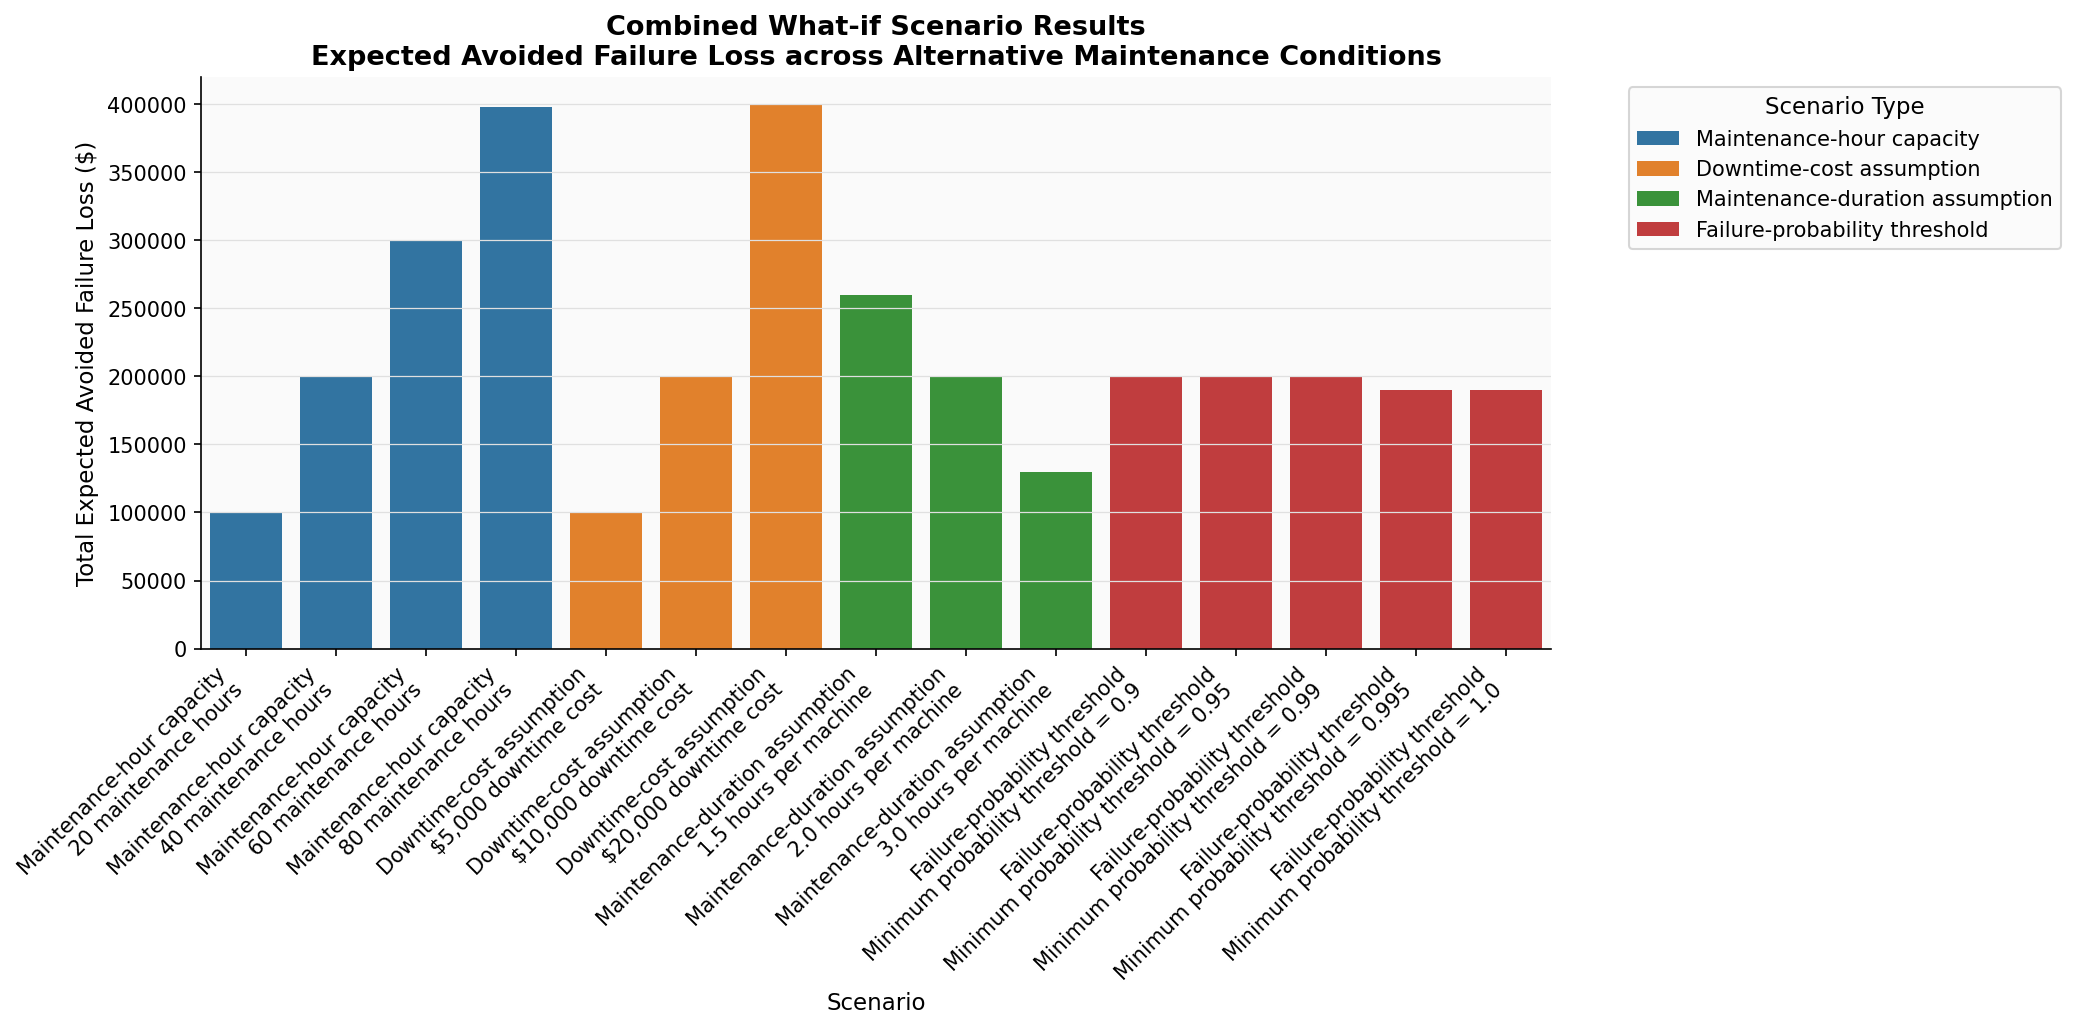

Saved: whatif_05_combined_scenario_summary.png


In [51]:
# ============================================================
# I11. Visualise Combined Scenario Outcomes
# ============================================================

plot_summary = combined_whatif_df.copy()

# Create readable labels
plot_summary["Scenario Label"] = (
    plot_summary["Scenario Type"] + "\n" + plot_summary["Scenario"].astype(str)
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=plot_summary,
    x="Scenario Label",
    y="Total expected avoided failure loss",
    hue="Scenario Type",
    dodge=False
)

plt.title(
    "Combined What-if Scenario Results\n"
    "Expected Avoided Failure Loss across Alternative Maintenance Conditions"
)
plt.xlabel("Scenario")
plt.ylabel("Total Expected Avoided Failure Loss ($)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Scenario Type", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.savefig(
    fig_folder / "whatif_05_combined_scenario_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: whatif_05_combined_scenario_summary.png")

### Combined What-if Scenario Interpretation

The combined scenario results show how the maintenance recommendation changes under different operational assumptions. Increasing available maintenance hours allows more machines to be selected and increases total expected avoided failure loss. Increasing downtime cost does not necessarily change which machines are selected when the cost multiplier is applied equally, but it increases the estimated business value of preventing failure. Longer maintenance duration reduces the number of machines that can be covered within the same 40-hour capacity. Higher probability thresholds restrict the candidate pool and may leave some maintenance capacity unused if too few machines meet the risk threshold.

Overall, the what-if analysis shows that the recommended maintenance allocation is most sensitive to maintenance-hour capacity and maintenance duration because these directly affect how many machines can be selected. Downtime cost mainly affects the estimated value of the selected allocation, while probability thresholds affect how strict the organisation wants to be in defining high-risk machines.

In [52]:
# ============================================================
# I12. Final Prescriptive Analytics Output Inventory
# ============================================================

prescriptive_output_files = [
    "prescriptive_base_case_summary.csv",
    "prescriptive_base_case_selected_machines.csv",
    "prescriptive_all_machine_decisions.csv",
    "whatif_maintenance_hour_sensitivity.csv",
    "whatif_downtime_cost_sensitivity.csv",
    "whatif_maintenance_duration_sensitivity.csv",
    "whatif_probability_threshold_sensitivity.csv",
    "whatif_combined_scenario_summary.csv"
]

prescriptive_figure_files = [
    "prescriptive_01_base_case_allocation.png",
    "prescriptive_02_selected_machine_expected_loss.png",
    "whatif_01_maintenance_hour_sensitivity.png",
    "whatif_02_downtime_cost_sensitivity.png",
    "whatif_03_maintenance_duration_sensitivity.png",
    "whatif_04_probability_threshold_sensitivity.png",
    "whatif_05_combined_scenario_summary.png"
]

print("Prescriptive analytics output files:")
print("=" * 70)

for file_name in prescriptive_output_files:
    file_path = output_folder / file_name
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status:<8} {file_name}")

print("\nPrescriptive analytics figure files:")
print("=" * 70)

for file_name in prescriptive_figure_files:
    file_path = fig_folder / file_name
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status:<8} {file_name}")

print("\nPrescriptive analytics and what-if scenario section completed.")

Prescriptive analytics output files:
FOUND    prescriptive_base_case_summary.csv
FOUND    prescriptive_base_case_selected_machines.csv
FOUND    prescriptive_all_machine_decisions.csv
FOUND    whatif_maintenance_hour_sensitivity.csv
FOUND    whatif_downtime_cost_sensitivity.csv
FOUND    whatif_maintenance_duration_sensitivity.csv
FOUND    whatif_probability_threshold_sensitivity.csv
FOUND    whatif_combined_scenario_summary.csv

Prescriptive analytics figure files:
FOUND    prescriptive_01_base_case_allocation.png
FOUND    prescriptive_02_selected_machine_expected_loss.png
FOUND    whatif_01_maintenance_hour_sensitivity.png
FOUND    whatif_02_downtime_cost_sensitivity.png
FOUND    whatif_03_maintenance_duration_sensitivity.png
FOUND    whatif_04_probability_threshold_sensitivity.png
FOUND    whatif_05_combined_scenario_summary.png

Prescriptive analytics and what-if scenario section completed.


## Prescriptive Analytics and What-if Scenario Summary

This section used the predicted failure probabilities from the best predictive model as inputs into a binary integer linear programming model. The optimisation selected machines for maintenance by maximising expected avoided failure loss while staying within the available maintenance-hour constraint.

The base-case scenario assumed 40 available maintenance hours, 2 hours per machine, and a downtime cost of $10,000 per failure. Additional what-if scenarios tested the robustness of the recommendation by varying maintenance capacity, downtime cost, maintenance duration, and minimum failure-probability thresholds.

The results support a risk-based maintenance allocation approach. Instead of treating all machines equally or relying only on fixed schedules, the organisation can prioritise maintenance for machines with the highest predicted failure risk while accounting for operational constraints.